# Notebook 2 · Optimización de objetivo único con PSO

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica
**UNAM · Instituto de Geología · Educación Continua y a Distancia · 10 de noviembre de 2026**
Dr. Abelardo Rodríguez Pretelín · Laboratorio HIDRA

En este notebook se muestra el uso de la herramienta **PSO** (enjambre de partículas) como optimizador para problemas de objetivo único: primero en
funciones de prueba cuyo óptimo conocemos, para aprender a usarla, y después en el acuífero de Fritz, primero en su versión lineal y después en una no lineal.

**Literatura:**

1. Clerc, M. (2010). *Particle Swarm Optimization* (Vol. 93). John Wiley & Sons.
2. Kennedy, J. y Eberhart, R. (1995). Particle swarm optimization. En *Proceedings of ICNN'95, International Conference on Neural Networks* (Vol. 4, pp. 1942–1948). IEEE.

---

### Cómo usar este cuaderno

- Ejecuta las celdas **en orden** con `Shift + Enter`. Algunas celdas tardan cerca de un minuto (lo dicen arriba): déjalas correr.
- Las cajas ✏️ **Tu turno** (tres, de dos minutos) dicen qué hacer, qué observar y una pregunta; la celda de abajo es tuya: cambia el número marcado con ← y vuelve a ejecutar. Al final de cada caja, plegado, está lo que debías ver.
- Las cajas ✔ **Punto de control · ⏸ Ejecuta hasta aquí** cierran las secciones 1, 2 y 3: dicen qué resultado debe verse. Ahí nos esperamos.
- Las figuras salen de funciones de `hidra` (`hidra.poblacion`, `hidra.convergencia`…): una línea dibuja; el código que se lee es el del algoritmo.
- El **Apéndice · en casa** guarda lo que no cabe en la sesión (tres ejemplos, dos animaciones y el barrido de precios). Corre después del cierre; no se ve en clase.

| Sección | Programa | Qué se hace |
|---|---|---|
| 1 | 2.3 · PSO introductorio | funciones de prueba: cómo se usa PSO, paso a paso y cuatro ejemplos de uso (16 min) |
| 2 | 2.4 · PSO hidrogeológico | el problema del original, **lineal**: PSO contra la verdad exacta de `linprog` (18 min) |
| 3 | 2.4 · PSO hidrogeológico | la ampliación **no lineal**: el beneficio neto, donde `linprog` ya no sirve (15 min) |
| 4 | puente | otra geología, otro óptimo (7 min) |
| A | en casa | ejemplos 4, 6 y 7, las dos animaciones y el precio |

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 0 · PREPARACIÓN</p>

## 0 · Preparación (2 min)

Además de `hidra` (el acuífero del curso, una carpeta arriba) usamos `pso.py`, que está en `Información/codigo` de esta sesión: un PSO completo en unas
100 líneas, sin nada escondido.

Importar dependencias:

In [1]:
import sys; sys.path.append('..'); sys.path.append('Información/codigo')   # hidra.py (arriba) y pso.py
import time                                                 # para medir tiempos
import numpy as np                                          # arreglos y cuentas numéricas
import matplotlib.pyplot as plt                             # gráficas
from scipy.optimize import linprog                          # programación lineal: la verdad exacta de la sesión 1

import hidra                          # el acuífero del curso
import pso                            # el enjambre de partículas del curso

hidra.verificar_entorno()                                   # comprueba que todo cargó: debe terminar con ENTORNO LISTO

Python 3.11.14 | numpy 2.4.1 | scipy 1.17.0 | matplotlib 3.10.8 | plotly 5.24.1 | otter 7.0.0
Simulador listo: una corrida tarda 0.04 s. Resultado(bombeos=[100.0, 100.0, 100.0] m³/d → abatimientos en pozos=[0.90, 0.92, 0.92] m, humedal=0.48 m)
ENTORNO LISTO


<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 1 · PSO CON FUNCIONES DE PRUEBA · PROGRAMA 2.3</p>

## 1 · PSO con funciones de prueba (16 min)

Antes de usar un optimizador en un acuífero conviene usarlo donde **conocemos la respuesta**.

### Función objetivo: Sphere

$$
f(\mathbf{x}) = \sum_{i=1}^{d} x_i^2
$$

**Descripción.** La función Sphere tiene un solo mínimo, el global: es continua, **convexa** y **unimodal** (un solo valle). Cualquier método que baje
la cuesta llega al fondo; sirve para comprobar que el optimizador funciona antes de darle algo difícil.

**Dominio.** Se evalúa normalmente en el hipercubo

$$
x_i \in [-5.12,\ 5.12], \quad \text{para todo} \quad i = 1, \ldots, d
$$

**Mínimo global.**

$$
f(\mathbf{x}^*) = 0, \quad \text{en} \quad \mathbf{x}^* = (0, \dots, 0)
$$

### 1.1 Definición de la función objetivo

In [2]:
# Función objetivo de muestra
def Sphere(x):                                              # recibe una decisión x (un arreglo) y devuelve un número
    return sum(x**2)                                        # la suma de los cuadrados: mínimo 0 en el origen

print(Sphere(np.array([0.0, 0.0])), Sphere(np.array([3.0, -4.0])))     # en el óptimo: 0 · en (3, -4): 9 + 16 = 25

0.0 25.0


👀 **La forma de la función.** Antes de optimizar, mírala completa. **Gírala con el mouse** (arrastra), acércate con la rueda y fíjate: tiene **un solo valle**, sin hoyos. Eso es una función **convexa**: desde cualquier punto, bajar la cuesta lleva al mínimo global, el rombo dorado en (0, 0). Ackley, más adelante, será muy distinta.

In [3]:
hidra.superficie_3d(Sphere, lim=(-5, 5), nombre='Sphere')      # 3-D interactiva: se gira con el mouse

### 1.2 Definir las condiciones del problema

In [4]:
# Definir el problema de optimización
problem = {                                                 # el diccionario que pso.PSO necesita
        'CostFunction': Sphere,                             # la función que califica
        'nVar': 2,                                          # cuántas variables tiene la decisión
        'VarMin': -5,                                       # frontera inferior de cada variable
        'VarMax': 5,                                        # frontera superior de cada variable
    }                                                       # fin del diccionario

### 1.3 Correr PSO

**Los parámetros del enjambre** son los de la lámina *Movimiento y posición*:

| Parámetro | Qué controla | Aquí |
|---|---|---|
| `PopSize` | cuántas partículas | 50 |
| `MaxIter` | cuántas iteraciones (pasos) | 200 |
| `w` | inercia: cuánto conserva cada partícula de su velocidad anterior | 1 |
| `wdamp` | amortiguamiento: en cada iteración, `w = w · wdamp` | 0.995 |
| `c1`, `c2` | atracción hacia su mejor posición propia (cognitiva) y hacia la mejor del enjambre (social) | 1.5 y 2 |
| `verbose` | `True` imprime el avance de cada iteración; `False` trabaja en silencio | `False` |

**Las ecuaciones.** Para cada partícula $i$, en cada iteración:

$$
\mathbf{v}_i \leftarrow \underbrace{w\,\mathbf{v}_i}_{\text{inercia}} + \underbrace{c_1\,\mathbf{r}_1 \odot (\mathbf{p}_i - \mathbf{x}_i)}_{\text{su propia experiencia}} + \underbrace{c_2\,\mathbf{r}_2 \odot (\mathbf{g} - \mathbf{x}_i)}_{\text{la experiencia del enjambre}}, \qquad
\mathbf{x}_i \leftarrow \mathbf{x}_i + \mathbf{v}_i
$$

**donde** $\mathbf{p}_i$ es la mejor posición que ha visitado la partícula, $\mathbf{g}$ la mejor de todo el enjambre y $\mathbf{r}_1, \mathbf{r}_2$ números al azar
entre 0 y 1 (uno por variable): son los que hacen al PSO **estocástico**. Costo de la corrida: 50 × 200 = **10 000 evaluaciones** de la función objetivo.

In [5]:
# Correr PSO
np.random.seed(0)                      # fija el azar: así todos vemos el mismo resultado
pso.tic()                                                   # arranca el cronómetro
print('Running PSO ...')                                    # aviso: empieza la corrida
gbest, pop = pso.PSO(problem, MaxIter = 200, PopSize = 50, c1 = 1.5, c2 = 2, w = 1, wdamp = 0.995, verbose = False)   # corre el enjambre: 50 partículas × 200 iteraciones; gbest = lo mejor, pop = las partículas
print()                                                     # renglón en blanco
pso.toc()                                                   # imprime cuánto tardó
print()                                                     # renglón en blanco

Running PSO ...



Elapsed time: 0.06 s



In [6]:
# Imprimir el resultado
print('Global Best:')                                       # encabezado
print(gbest)                                                # la mejor posición encontrada y su costo
print()                                                     # renglón en blanco

Global Best:
{'position': array([ 4.57387833e-15, -1.03155035e-14]), 'cost': np.float64(1.273299744429373e-28)}



👀 **El enjambre en movimiento.** La misma corrida de arriba (misma semilla), pero guardando dónde está cada partícula en cada iteración. Dale **▶ correr** o mueve la barra: a la izquierda, desde arriba; a la derecha, en 3-D (puedes **girarla** mientras corre). Fíjate cómo el enjambre empieza disperso, **explorando**, y se contrae hacia (0, 0), **explotando**. Bastan las primeras 60 iteraciones: después todas están encimadas en el fondo.

In [7]:
np.random.seed(0)                       # la misma semilla de arriba: es la misma corrida
H, H_costo, H_g = hidra.registrar_pso(problem, MaxIter = 60, PopSize = 50, c1 = 1.5, c2 = 2, w = 1, wdamp = 0.995)   # guarda cada iteración
hidra.animar_enjambre_interactivo(H, H_costo, H_g, Sphere, lim = (-5, 5), nombre = 'Sphere')   # ▶ para correr; se gira con el mouse

<div style="border-left: 6px solid #2E9BB5; background: #E2EFF2; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✏️ Tu turno 1 · ¿Con cuántas evaluaciones te conformas?</b> <span style="color:#54696F; font-size:0.8em;">· 2 min · la celda de abajo es tuya</span></p>
<p style="margin: 0;"><b style="color:#0B5B72;">Qué hacer</b></p>
<ol style="margin: 2px 0 8px 0; padding-left: 1.4em;"><li>Ejecuta la celda tal como está: 10 partículas × 20 iteraciones = 200 evaluaciones, cincuenta veces menos que arriba.</li><li>Cambia los dos números de la primera línea (prueba 20 × 50 y 50 × 100) y vuelve a ejecutar.</li></ol>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Qué observar</b> · el mejor costo que imprime, frente al de arriba (50 × 200 = 10 000 evaluaciones: del orden de 10⁻²⁸).</p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Pregunta</b> · si la meta fuera un costo menor que 0.001, ¿cuál es el presupuesto más chico que te sirve?</p>
<details style="margin-top: 4px;"><summary style="cursor: pointer; color:#C08A0B;"><b>Cuando termines: lo que debías ver</b></summary>
<p style="margin: 4px 0 0 0;">Con 10 × 20 el mejor costo queda cerca de 2.7 × 10⁻³: todavía no. Con 20 × 50 baja a 6.4 × 10⁻⁵ y con 50 × 100 a 7.4 × 10⁻⁹. El presupuesto compra decimales; cuántos necesitas lo decide el problema, no el algoritmo: para Fritz bastan dos.</p></details>
</div>

In [8]:
PopSize_tt, MaxIter_tt = 10, 20          # ← cambia estos dos números
np.random.seed(0)                                           # fija el azar: así todos vemos el mismo resultado
g_tt, _ = pso.PSO(problem, MaxIter=MaxIter_tt, PopSize=PopSize_tt, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)   # el mismo enjambre con tu presupuesto
print(f"{PopSize_tt} partículas × {MaxIter_tt} iteraciones = {PopSize_tt * MaxIter_tt} evaluaciones -> mejor costo {g_tt['cost']:.2e} en {np.round(g_tt['position'], 3)}")   # cuántas evaluaciones y a qué costo llegó

10 partículas × 20 iteraciones = 200 evaluaciones -> mejor costo 2.72e-03 en [-0.018  0.049]


### 1.4 Visualizar resultado

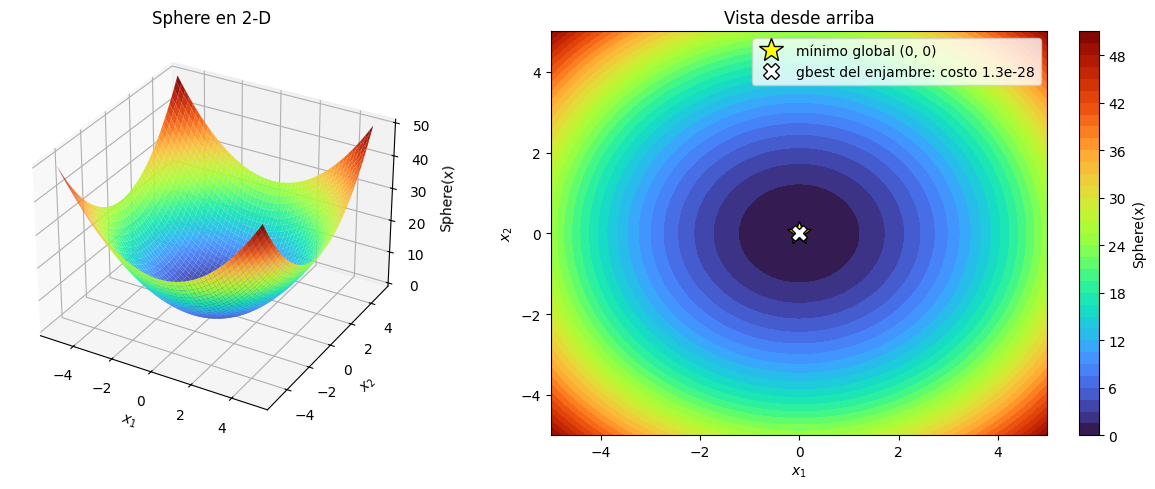

In [9]:
hidra.superficie_prueba(Sphere, lim=(problem['VarMin'], problem['VarMax']), gbest=gbest, nombre='Sphere')   # la superficie y, desde arriba, dónde quedó gbest

### 1.5 Paso a paso en el algoritmo

`pso.PSO` no tiene magia. Aquí está el mismo algoritmo escrito a la vista, en los bloques del cuaderno original, para que reconozcas cada término
de la ecuación de velocidad.

**Bloque 1: parámetros.**

In [10]:
CostFunction = Sphere                                       # la función que califica
nVar, VarMin, VarMax = 2, -5, 5                             # 2 variables, cada una entre −5 y 5
MaxIter, PopSize = 50, 20                                   # 50 iteraciones, 20 partículas
w, wdamp, c1, c2 = 1.0, 0.95, 1.5, 2.0                      # inercia, su amortiguación, peso de la memoria y peso del grupo
np.random.seed(1)                                           # fija el azar (semilla 1)

👀 **Lo que acabamos de definir, en un dibujo:** el terreno de juego (el dominio de Sphere) y los parámetros del enjambre.

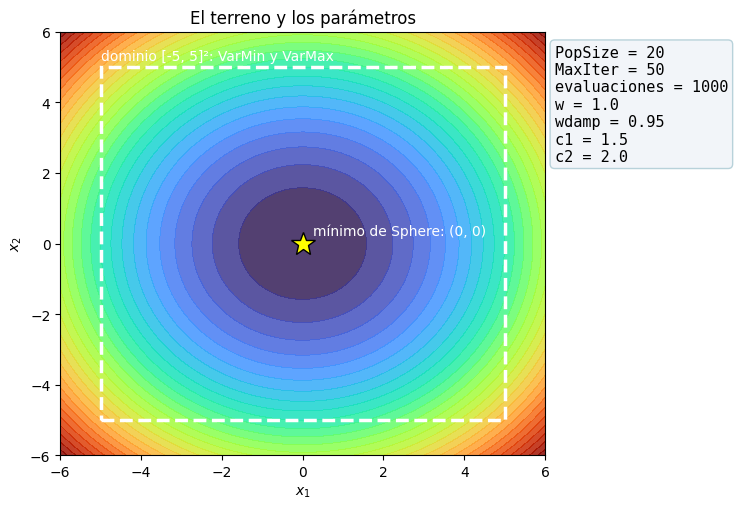

In [11]:
hidra.terreno_parametros(Sphere, VarMin, VarMax, {'PopSize': PopSize, 'MaxIter': MaxIter, 'evaluaciones': PopSize * MaxIter, 'w': w, 'wdamp': wdamp, 'c1': c1, 'c2': c2})   # el terreno de juego y la ficha de parámetros

**Bloque 2: la población inicial.** Cada partícula nace en un lugar al azar del dominio, quieta (velocidad cero). Su mejor posición propia, de momento,
es donde nació. El mejor global es la mejor de todas.

In [12]:
# Template de la particula
empty_particle = {'position': None, 'velocity': None, 'cost': None, 'best_position': None, 'best_cost': None}   # el molde de una partícula: cinco datos, todavía vacíos

# Crear población inicial
pop = []                                                    # lista vacía: aquí se guardará el enjambre (una partícula por elemento)
gbest = {'position': None, 'cost': np.inf}                  # lo mejor del grupo; empieza con costo infinito
for i in range(0, PopSize):                                 # una vuelta por cada partícula
    pop.append(empty_particle.copy())                       # añade a la lista una copia del molde
    pop[i]['position'] = np.random.uniform(VarMin, VarMax, nVar)   # nace en un punto al azar del dominio
    pop[i]['velocity'] = np.zeros(nVar)                     # nace quieta: velocidad cero
    pop[i]['cost'] = CostFunction(pop[i]['position'])       # se califica su posición
    pop[i]['best_position'] = pop[i]['position'].copy()     # su mejor punto p pasa a ser la posición actual
    pop[i]['best_cost'] = pop[i]['cost']                    # y guarda su costo
    if pop[i]['best_cost'] < gbest['cost']:                 # ¿es mejor que lo mejor del grupo?
        gbest['position'] = pop[i]['best_position'].copy()   # pasa a ser g, lo mejor del grupo
        gbest['cost'] = pop[i]['best_cost']                 # con su costo

print(f"{PopSize} partículas creadas. Mejor costo inicial: {gbest['cost']:.4f} en {np.round(gbest['position'], 3)}")   # resumen de la población inicial

20 partículas creadas. Mejor costo inicial: 1.0283 en [-0.827  0.587]


👀 **Cómo se ve la «librería» de partículas.** `pop` es una lista con un diccionario por partícula; cada diccionario guarda dónde está, cuánto se mueve, qué tan buena es y lo mejor que ha visto. A la izquierda, las mismas partículas sobre el terreno; a la derecha, la tabla con las primeras ocho. Todas nacen quietas (`velocity` = 0) y su mejor posición es donde nacieron.

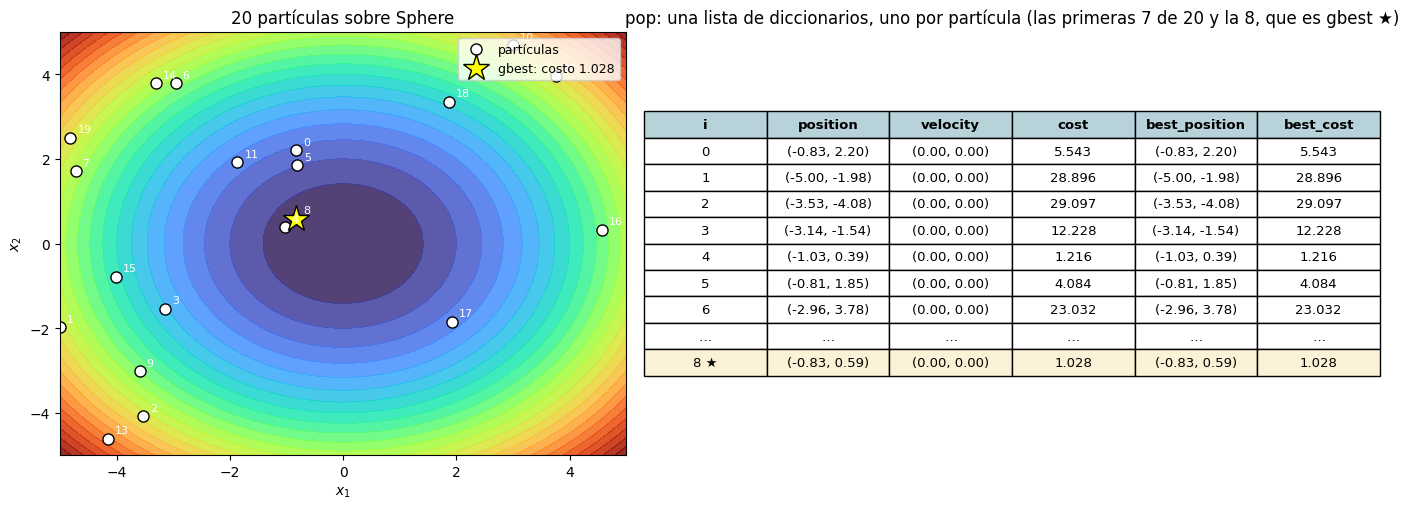

In [13]:
hidra.poblacion(pop, gbest, Sphere, VarMin, VarMax)         # la población como tabla y en el mapa

**Bloque 3: el ciclo principal.** Cada iteración mueve a todas las partículas con las dos ecuaciones, las evalúa y actualiza las memorias.

In [14]:
# PSO Loop principal
for it in range(0, MaxIter):                                # una vuelta por iteración
    for i in range(0, PopSize):                             # una vuelta por cada partícula

        pop[i]['velocity'] = w * pop[i]['velocity'] \
            + c1 * np.random.rand(nVar) * (pop[i]['best_position'] - pop[i]['position']) \
            + c2 * np.random.rand(nVar) * (gbest['position'] - pop[i]['position'])      # 1 inercia · 2 su experiencia · 3 la del enjambre

        pop[i]['position'] += pop[i]['velocity']                                       # la ecuación de posición
        pop[i]['position'] = np.clip(pop[i]['position'], VarMin, VarMax)               # acotamiento: no salir del dominio

        pop[i]['cost'] = CostFunction(pop[i]['position'])                              # evaluar: aquí iría la corrida del simulador

        if pop[i]['cost'] < pop[i]['best_cost']:                                       # ¿mejoró su propio récord?
            pop[i]['best_position'] = pop[i]['position'].copy()   # su mejor punto p pasa a ser la posición actual
            pop[i]['best_cost'] = pop[i]['cost']            # y guarda su costo
            if pop[i]['best_cost'] < gbest['cost']:                                    # ¿mejoró el récord del enjambre?
                gbest['position'] = pop[i]['best_position'].copy()   # pasa a ser g, lo mejor del grupo
                gbest['cost'] = pop[i]['best_cost']         # con su costo

    w *= wdamp                                                                         # la inercia se amortigua

print(f"Después de {MaxIter} iteraciones ({MaxIter * PopSize} evaluaciones): mejor costo = {gbest['cost']:.2e} en {np.round(gbest['position'], 5)}")   # el resultado del paso a paso

Después de 50 iteraciones (1000 evaluaciones): mejor costo = 2.00e-17 en [-0. -0.]


👀 **El ciclo, visto por fuera.** La misma corrida (misma semilla) guardando dónde estuvo cada partícula en cada iteración: cuatro instantes del enjambre y la curva de convergencia del mejor costo. Al principio exploran; al final se juntan en el fondo del valle.

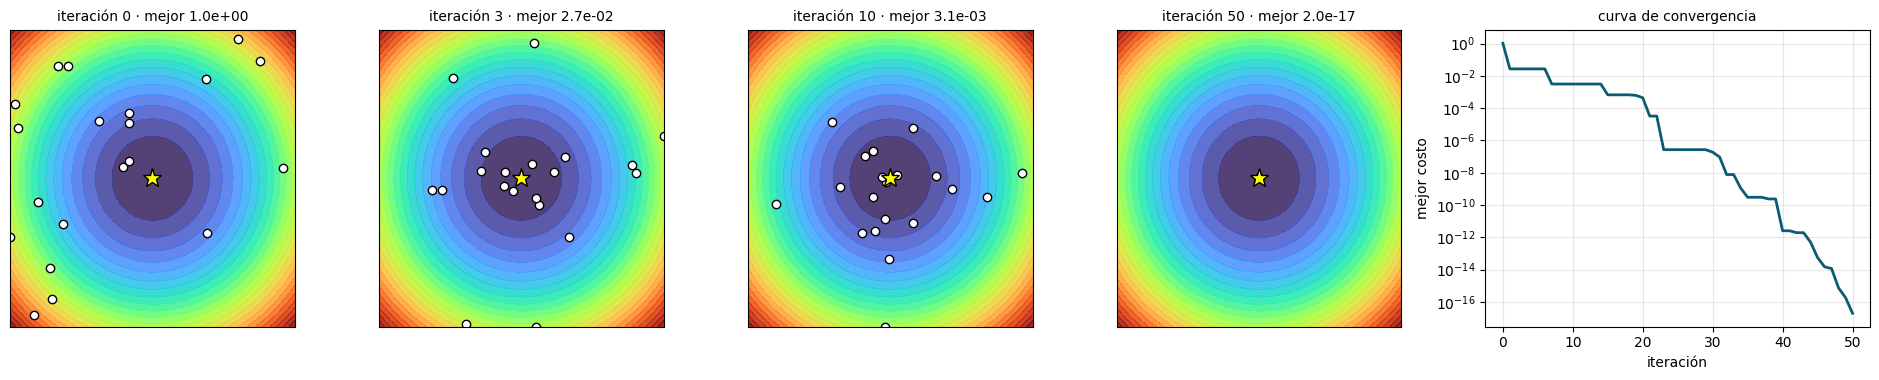

la historia guardada: H_pp tiene forma (51, 20, 2) = (iteraciones + 1, partículas, variables); el mejor costo final 2.00e-17, como arriba


In [15]:
np.random.seed(1)                                           # la misma semilla del bloque 1: es la misma corrida
H_pp, Hg_pp, _ = hidra.registrar_pso({'CostFunction': Sphere, 'nVar': nVar, 'VarMin': VarMin, 'VarMax': VarMax},
                                     MaxIter=MaxIter, PopSize=PopSize, c1=c1, c2=c2, w=1.0, wdamp=wdamp)   # repite la corrida guardando cada iteración (w vuelve a empezar en 1)
hidra.instantes(H_pp, Hg_pp, Sphere, VarMin, VarMax, iteraciones=(0, 3, 10, MaxIter))   # el enjambre en las iteraciones 0, 3, 10 y 50, y su curva de convergencia
print(f"la historia guardada: H_pp tiene forma {H_pp.shape} = (iteraciones + 1, partículas, variables); el mejor costo final {Hg_pp[-1]:.2e}, como arriba")   # qué se guardó

<div style="border-left: 6px solid #2E9BB5; background: #E2EFF2; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✏️ Tu turno 2 · Apaga la cooperación, apaga la memoria</b> <span style="color:#54696F; font-size:0.8em;">· 2 min · la celda de abajo es tuya</span></p>
<p style="margin: 0;"><b style="color:#0B5B72;">Qué hacer</b></p>
<ol style="margin: 2px 0 8px 0; padding-left: 1.4em;"><li>Ejecuta la celda tal como está: es la corrida del paso a paso (misma semilla, 20 × 50) pero con <code>c2 = 0</code>: nadie escucha al enjambre.</li><li>Pon <code>c1_tt, c2_tt = 0.0, 2.0</code> (nadie recuerda lo suyo) y vuelve a ejecutar.</li><li>Vuelve a <code>1.5, 2.0</code> para recuperar el resultado de arriba.</li></ol>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Qué observar</b> · el mejor costo final de cada corrida, frente al 2.00 × 10⁻¹⁷ del paso a paso.</p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Pregunta</b> · ¿cuál de los dos términos es indispensable aquí? ¿Por qué con <code>c2 = 0</code> el enjambre ni siquiera se mueve?</p>
<details style="margin-top: 4px;"><summary style="cursor: pointer; color:#C08A0B;"><b>Cuando termines: lo que debías ver</b></summary>
<p style="margin: 4px 0 0 0;">Con c₂ = 0 el costo se queda en 1.03, el de la población inicial: la velocidad arranca en cero y p = x, así que ningún término empuja y nadie se mueve. Con c₁ = 0 llega igual (≈10⁻¹⁸): en un valle sin trampas la memoria sobra. Con los dos, 2 × 10⁻¹⁷. Es el dilema cooperación contra competencia de las láminas: aquí gana la cooperación; en Ackley (ejemplo 3) la memoria vuelve a importar.</p></details>
</div>

In [16]:
c1_tt, c2_tt = 1.5, 0.0                  # ← prueba (1.5, 0.0), (0.0, 2.0) y (1.5, 2.0)
np.random.seed(1)                                           # fija el azar (semilla 1)
g_tt, _ = pso.PSO(problem, MaxIter=50, PopSize=20, c1=c1_tt, c2=c2_tt, w=1.0, wdamp=0.95, verbose=False)   # el paso a paso con tus c1 y c2
print(f"c1 = {c1_tt}, c2 = {c2_tt}: mejor costo {g_tt['cost']:.2e} en {np.round(g_tt['position'], 4)}   (20 partículas × 50 iteraciones en Sphere)")   # a qué costo llegó

c1 = 1.5, c2 = 0.0: mejor costo 1.03e+00 en [-0.827   0.5869]   (20 partículas × 50 iteraciones en Sphere)


Eso es todo el PSO. `pso.py` hace exactamente lo mismo, con dos añadidos que usaremos en la sección 2: puede **maximizar** (`'MinProblem': 0`) y puede
**reparar** cada posición con una función (`'ResFunction'`).

### 1.6 Ejemplos de uso del algoritmo

Ejemplos cortos para aprender a **usar** PSO: qué devuelve, qué mover y qué esperar. En la sesión vemos los ejemplos 1, 2, 3 y 5; los ejemplos 4, 6 y 7 están en el **Apéndice · en casa**, al final del cuaderno.

#### Ejemplo 1 · ¿Qué devuelve PSO?

`pso.PSO` devuelve `gbest` (la mejor posición y su costo) y `pop` (todas las partículas al final). Además, `pso.historial` guarda el mejor costo de cada
iteración: con él se dibuja la **curva de convergencia**.

gbest tiene las llaves: ['position', 'cost'] | pop es una lista de 50 partículas con llaves ['position', 'velocity', 'cost', 'best_position', 'best_cost']


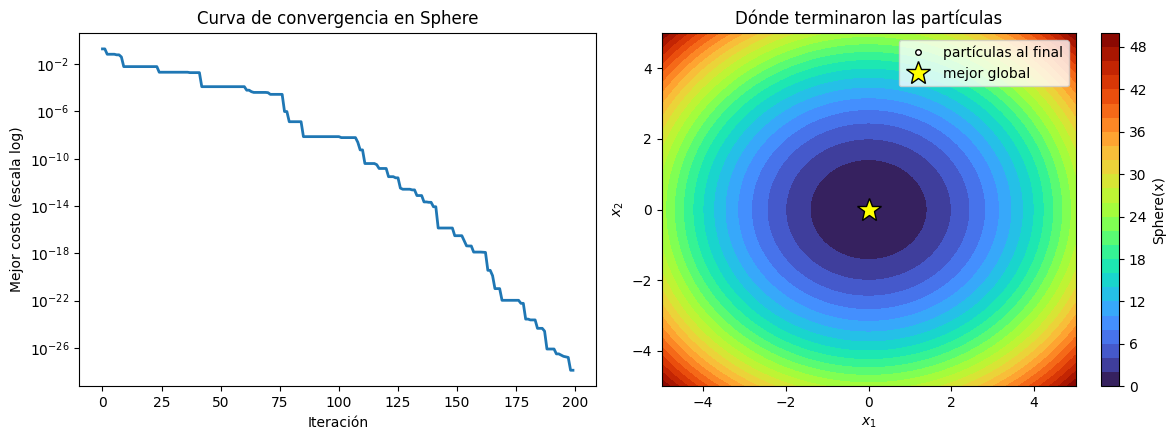

In [17]:
np.random.seed(0)                                           # fija el azar: así todos vemos el mismo resultado
gbest, pop = pso.PSO(problem, MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)   # corre el enjambre: 50 × 200
print("gbest tiene las llaves:", list(gbest.keys()), "| pop es una lista de", len(pop), "partículas con llaves", list(pop[0].keys()))   # qué contiene lo que devolvió

hidra.resultado_enjambre(pso.historial, pop, gbest, Sphere, problem['VarMin'], problem['VarMax'])   # la curva de convergencia y dónde quedaron las partículas

👀 **Cómo se consulta cada cosa.** Tres celdas con lo que se escribe para leer el resultado: primero `gbest`, después una partícula cualquiera de `pop`, y por último `pso.historial`. Cambia los índices y vuelve a ejecutar.

In [18]:
# 1 · gbest: un diccionario con dos llaves
print("gbest completo:", gbest)                             # el diccionario entero
print("la mejor posición encontrada:", gbest['position'])   # se lee con la llave 'position'
print("su costo:", gbest['cost'])                           # y con la llave 'cost'
print("como número con formato: costo = {:.2e}, x1 = {:.4f}, x2 = {:.4f}".format(gbest['cost'], gbest['position'][0], gbest['position'][1]))   # lo mismo, con decimales a la medida

gbest completo: {'position': array([ 4.57387833e-15, -1.03155035e-14]), 'cost': np.float64(1.273299744429373e-28)}
la mejor posición encontrada: [ 4.57387833e-15 -1.03155035e-14]
su costo: 1.273299744429373e-28
como número con formato: costo = 1.27e-28, x1 = 0.0000, x2 = -0.0000


In [19]:
# 2 · pop: una lista de partículas; cada partícula es un diccionario con cinco llaves
print("pop tiene", len(pop), "partículas; la primera es:")   # cuántas partículas hay
print(pop[0])                                               # la primera partícula: un diccionario con sus cinco datos
print()                                                     # renglón en blanco
p7 = pop[7]                                         # ← cambia el índice: de 0 a 49
fmt = lambda v: "(" + ", ".join(f"{x:.2e}" for x in v) + ")"      # al final de la corrida los números son diminutos: mejor en notación científica
print("partícula 7: está en", fmt(p7['position']), "| se mueve con velocidad", fmt(p7['velocity']), "| su costo ahora", f"{p7['cost']:.2e}")   # dónde está, cómo se mueve y cuánto vale
print("            lo mejor que ha visto:", fmt(p7['best_position']), "con costo", f"{p7['best_cost']:.2e}")   # su memoria: p y su costo
costos_finales = np.array([p['cost'] for p in pop])         # el costo final de cada partícula
print(f"\ncostos finales de las 50: mínimo {costos_finales.min():.2e}, mediana {np.median(costos_finales):.2e}, máximo {costos_finales.max():.2e}")   # resumen de los 50 costos
print("¿cuál partícula es la mejor al final?", int(np.argmin([p['best_cost'] for p in pop])), "-> su best_cost coincide con gbest['cost']:", min(p['best_cost'] for p in pop) == gbest['cost'])   # la mejor partícula coincide con gbest

pop tiene 50 partículas; la primera es:
{'position': array([-1.13669345e-12,  3.22552444e-12]), 'velocity': array([ 2.69053862e-12, -7.42782775e-13]), 'cost': np.float64(1.1696079948991639e-23), 'best_position': array([-1.13669345e-12,  3.22552444e-12]), 'best_cost': np.float64(1.1696079948991639e-23)}

partícula 7: está en (-4.86e-10, -3.85e-10) | se mueve con velocidad (1.73e-09, -9.83e-10) | su costo ahora 3.84e-19
            lo mejor que ha visto: (-4.86e-10, -3.85e-10) con costo 3.84e-19

costos finales de las 50: mínimo 1.41e-28, mediana 8.35e-24, máximo 5.10e-17
¿cuál partícula es la mejor al final? 18 -> su best_cost coincide con gbest['cost']: True


In [20]:
# 3 · pso.historial: el mejor costo al final de cada iteración (una lista de MaxIter números)
print("iteraciones registradas:", len(pso.historial))       # un número por iteración
print("las primeras cinco:", [f"{h:.3g}" for h in pso.historial[:5]])   # el inicio de la curva
print("las últimas tres:  ", [f"{h:.3g}" for h in pso.historial[-3:]])   # el final de la curva
print("la mejor (la última, porque nunca empeora):", f"{pso.historial[-1]:.2e}", "= gbest['cost']:", pso.historial[-1] == gbest['cost'])   # el último valor es gbest
umbral = 1e-6                                               # ¿cuándo se considera «llegó»?
print(f"¿en qué iteración bajó de {umbral:g}? en la", int(np.argmax(np.array(pso.historial) < umbral)))   # la primera iteración por debajo del umbral

iteraciones registradas: 200
las primeras cinco: ['0.195', '0.195', '0.0687', '0.0687', '0.0687']
las últimas tres:   ['1.55e-27', '1.27e-28', '1.27e-28']
la mejor (la última, porque nunca empeora): 1.27e-28 = gbest['cost']: True
¿en qué iteración bajó de 1e-06? en la 77


#### Ejemplo 2 · El presupuesto: partículas por iteraciones

Cada evaluación cuesta. En el acuífero, cada evaluación será una corrida del simulador. ¿Cuánto presupuesto hace falta en Sphere de 5 variables?

In [21]:
problema_sphere5 = dict(problem, nVar=5)                    # el mismo problema, con 5 variables
print("partículas  iteraciones  evaluaciones   mejor costo")   # encabezado de la tabla
for pop_size, max_iter in [(10, 20), (20, 50), (50, 100), (50, 200)]:   # cuatro presupuestos
    np.random.seed(0)                                       # fija el azar: así todos vemos el mismo resultado
    g, _ = pso.PSO(problema_sphere5, MaxIter=max_iter, PopSize=pop_size, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)   # corre con ese presupuesto
    print(f"{pop_size:10d} {max_iter:12d} {pop_size * max_iter:13d}   {g['cost']:.2e}")   # un renglón de la tabla

partículas  iteraciones  evaluaciones   mejor costo
        10           20           200   3.45e-01


        20           50          1000   4.21e-01
        50          100          5000   1.27e-04
        50          200         10000   3.13e-19


En general, más presupuesto da mejor resultado (con una sola semilla hay excepciones: lo vemos en el ejemplo 5), pero no es gratis. En un modelo regional de una hora por corrida, 10 000 evaluaciones son más de un año de cómputo:
el presupuesto manda.

#### Ejemplo 3 · Paisajes con trampas: Ackley

La función **Ackley** tiene su mínimo global también en el origen, pero rodeado de **cientos de mínimos locales**:

$$
f(\mathbf{x}) = -20\,\exp\!\left(-0.2\sqrt{\tfrac{1}{d}\textstyle\sum_{i} x_i^2}\right) - \exp\!\left(\tfrac{1}{d}\textstyle\sum_{i}\cos(2\pi x_i)\right) + 20 + e
$$

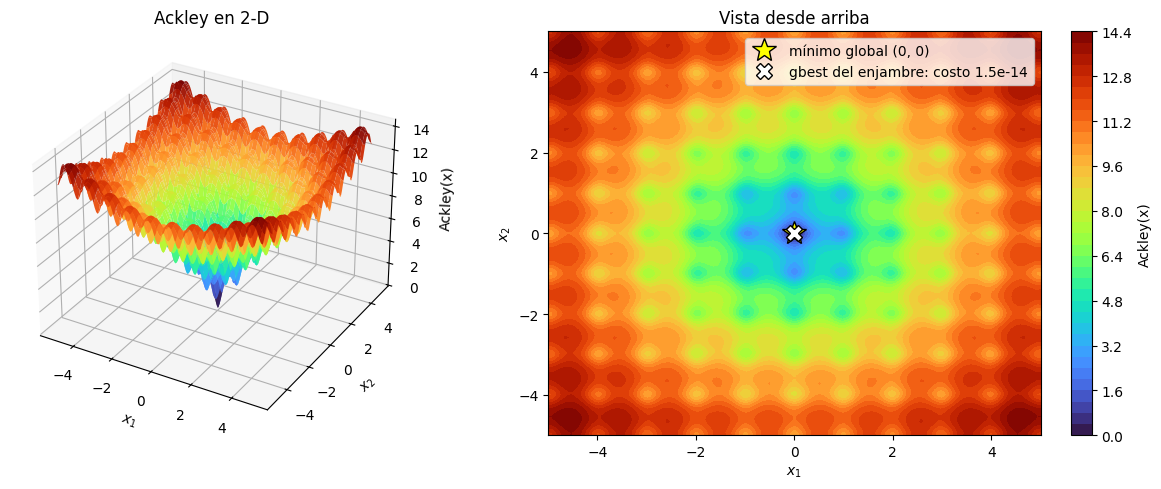

In [22]:
def Ackley(x):                                              # la función con muchos mínimos locales
    d = len(x)                                              # cuántas variables
    termino1 = -20 * np.exp(-0.2 * np.sqrt(np.sum(x**2) / d))     # el embudo grande
    termino2 = -np.exp(np.sum(np.cos(2 * np.pi * x)) / d)          # las ondulaciones: los mínimos locales
    return termino1 + termino2 + 20 + np.e                  # + 20 + e: el mínimo global vale 0, en el origen


problema_ackley = {'CostFunction': Ackley, 'nVar': 2, 'VarMin': -5, 'VarMax': 5}   # Ackley en 2 variables
np.random.seed(0)                                           # fija el azar: así todos vemos el mismo resultado
g_ack, _ = pso.PSO(problema_ackley, MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)   # el enjambre sobre Ackley

hidra.superficie_prueba(Ackley, lim=(-5, 5), gbest=g_ack, nombre='Ackley')   # la superficie y dónde quedó gbest

En dos dimensiones el enjambre encuentra el origen. El problema aparece cuando crece la dimensión: con $d = 10$ variables y el dominio estándar,
$x_i \in [-32.768,\ 32.768]$, el espacio es astronómicamente mayor (la **maldición de la dimensionalidad**). El ejemplo 5 (y el 4, en el apéndice) usan ese caso.

#### Ejemplo 5 · Una corrida no es un resultado

PSO es **estocástico**: con otra semilla, otra respuesta. Un resultado de metaheurística se reporta como **estadística de varias corridas**.

media = 0.3468 | desviación = 0.5292 | mejor = 1.64e-04 | peor = 1.1552
corridas atrapadas en un mínimo local (costo > 0.1): 3 de 10


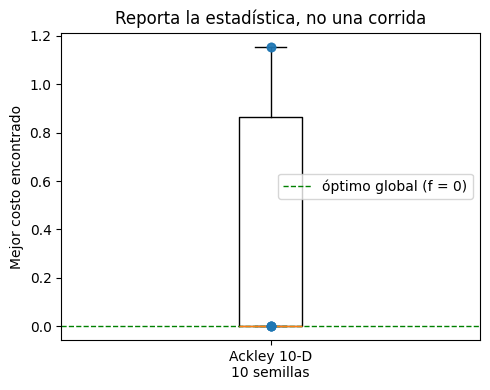

In [23]:
problema_ackley10 = {'CostFunction': Ackley, 'nVar': 10, 'VarMin': -32.768, 'VarMax': 32.768}   # Ackley en 10 variables, en su dominio estándar
resultados = []                                             # aquí se guarda el costo final de cada semilla
for semilla in range(10):                                   # diez corridas, una por semilla
    np.random.seed(semilla)                                 # cambia solo la semilla
    g, _ = pso.PSO(problema_ackley10, MaxIter=200, PopSize=20, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)   # el mismo enjambre: 20 × 200
    resultados.append(g['cost'])                            # guarda el costo final
resultados = np.array(resultados)                           # a arreglo, para sacar estadística
print(f"media = {resultados.mean():.4f} | desviación = {resultados.std():.4f} | mejor = {resultados.min():.2e} | peor = {resultados.max():.4f}")   # una corrida no es un resultado: la estadística de diez
print(f"corridas atrapadas en un mínimo local (costo > 0.1): {(resultados > 0.1).sum()} de 10")   # cuántas se atoraron

hidra.estadistica_corridas(resultados, etiqueta='Ackley 10-D\n10 semillas')   # el diagrama de caja de las diez

La receta es siempre la misma: **(1)** una función que califica una decisión, **(2)** el diccionario `problem` (con `MinProblem` y `ResFunction` si
hacen falta), **(3)** los parámetros del enjambre, **(4)** `pso.PSO`. Es justo lo que haremos con el acuífero. (El ejemplo 6 del apéndice la aplica a una función propia, con `MinProblem` y `ResFunction`.)

<div style="border-left: 6px solid #C08A0B; background: #FBF1D6; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✔ Punto de control 1 · ⏸ Ejecuta hasta aquí</b> <span style="color:#54696F; font-size:0.8em;">· minuto 18 del cuaderno</span></p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Debes ver</b> · Debes ver: Sphere con costo del orden de 10⁻²⁸ en (0, 0), cero numérico; el paso a paso con 20 partículas llega a ~10⁻¹⁷; en Ackley 10-D con diez semillas, <b>3 de 10 corridas atrapadas</b> (costo &gt; 0.1).</p>
<p style="margin: 0; color:#54696F;">Si tu resultado no coincide, avisa en el chat antes de seguir; si coincide, espera: seguimos juntos.</p>
</div>

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 2 · EL PROBLEMA HIDROGEOLÓGICO, LINEAL · PROGRAMA 2.4</p>

## 2 · El problema de Fritz, lineal (18 min)

### 2.1 Descripción del problema

Un propietario, Fritz, controla tres pozos de extracción de agua subterránea en el acuífero del curso (el de las sesiones 1 a 4, que simula `hidra`).

- El acuífero es **confinado** y el flujo está en **estado estacionario**.
- El **pozo 3** tiene un contrato: debe extraer **300 m³/d** constantes.
- El abatimiento en cualquier pozo no debe exceder **3 m**.
- El abatimiento en el **humedal** no debe exceder **1.25 m** (en el cuaderno original, el agotamiento del arroyo no debía exceder 1 400 m³/d).

**Pregunta.** Fritz quiere saber la cantidad máxima que puede bombear de manera constante de los tres pozos sin causar abatimientos indeseables ni dañar el humedal.

Este problema tiene solo dos variables libres ($p_1$ y $p_2$). Para ilustrar también el efecto del bombeo conocido del pozo 3, lo incluimos en la función objetivo.

#### Definición de la función objetivo

$$
\max Z = \sum_{i=1}^{M^{p}=3} p_{i}
$$

Sujeta a las siguientes condiciones / restricciones:

$$
p_1, p_2 \geq 0, \qquad p_3 = 300, \qquad s_1, s_2, s_3 \leq 3\ \text{m}, \qquad s_h \le 1.25\ \text{m}
$$

**donde** $p_i$ es el bombeo del pozo $i$ (m³/d), $s_j = \sum_i \alpha_{ji}\,p_i$ el abatimiento en el pozo $j$ y $s_h = \sum_i \alpha_{h,i}\,p_i$ el abatimiento en el
humedal, con la matriz de respuesta $\alpha$ que el simulador fabrica (sesión 1).

| Cuaderno original | Aquí |
|---|---|
| matriz $\alpha$ de Peralta (tabla) | matriz $\alpha$ de Fritz, fabricada con el simulador (`hidra`) |
| arroyo: $\beta \cdot p \le 1\,400$ m³/d | humedal: $\alpha_h \cdot p \le 1.25$ m |
| pozo 3 fijo en 600 m³/d | pozo 3 fijo en 300 m³/d (el acuífero de Fritz es menos transmisivo) |

#### a · Definir la función objetivo

Es la función `Pumping` del original: simula, comprueba las restricciones y califica. Si alguna regla se rompe, la calificación **cambia de signo**
($-\sum p_i$): esa es la manera en que el original castiga.

In [24]:
alpha = hidra.matriz_respuesta()          # 3 x 3: metros de abatimiento en cada pozo por cada m³/d de cada pozo
alpha_h = hidra.coeficientes_humedal()    # lo mismo, en el humedal
S_MAX, S_HUM, P3 = hidra.S_MAX, hidra.S_MAX_HUMEDAL, hidra.P3_COMPROMETIDO     # 3 m, 1.25 m y 300 m³/d

# Función objetivo de muestra
def Pumping(x):                                             # la función que califica una decisión de bombeo

    # 1.- Simulación (con la matriz de respuesta)
    s_sim = alpha @ x          # abatimiento en los tres pozos
    s_hum = alpha_h @ x        # abatimiento en el humedal

    # 2.- Integrar restricciones: si se respetan, el bombeo total; si no, el bombeo total con signo negativo
    if (s_sim <= S_MAX).all() and s_hum <= S_HUM:           # ¿se cumplen todas las reglas de abatimiento?
        cost = np.sum(x)                                    # sí: la calificación es el bombeo total
    else:                                                   # si no:
        cost = -np.sum(x)                                   # el bombeo total con signo negativo (castigo de signo)

    return cost                                             # la calificación

print(Pumping(np.array([300.0, 100.0, P3])), Pumping(np.array([500.0, 500.0, P3])))   # dos pruebas: 700 (cumple) y −1 300 (rompe)

700.0 -1300.0


#### b · Definir las restricciones del problema

La restricción $p_3 = 300$ no se castiga: se **repara**. Después de cada movimiento, PSO aplica esta función a la partícula.

In [25]:
# Integrar restricción a las variables de decisión
def Restriction(x):                                         # la reparación: se aplica a cada partícula al crearla y al moverla
    x[2] = P3                                               # el pozo 3 vuelve a su contrato, 300
    return x                                                # la decisión reparada

**¿Quién llama a `Restriction`?** Nosotros solo la definimos; la usa `pso.PSO`. En la sección 2.3 se la daremos con una llave del diccionario:
`'ResFunction': Restriction`. Al leer el diccionario, `pso.PSO` la guarda (`Restriction = problem.get('ResFunction', None)`) y la llama **sola**,
con cada partícula, en dos momentos:

```python
# dentro de pso.py, al crear cada partícula:
pop[i]['position'] = np.random.uniform(VarMin, VarMax, nVar)   # nace al azar: el pozo 3 en cualquier valor de 0 a 1 000
if Restriction is not None:
    pop[i]['position'] = Restriction(pop[i]['position'])       # ← aquí: el pozo 3 vuelve a 300

# y en el ciclo, después de mover cada partícula y antes de calificarla:
pop[i]['position'] += pop[i]['velocity']                       # se mueve
pop[i]['position'] = np.maximum(pop[i]['position'], VarMin)   # se recorta a las fronteras
pop[i]['position'] = np.minimum(pop[i]['position'], VarMax)
if Restriction is not None:
    pop[i]['position'] = Restriction(pop[i]['position'])       # ← y aquí
```

**Sin esa llave** (`Restriction` valdría `None`), las partículas nacerían con el pozo 3 en cualquier valor y se quedarían ahí: el enjambre resolvería
otro problema, sin contrato. Cada llave del diccionario hace su trabajo:

| Llave | Qué le dice a `pso.PSO` | Cuándo la usa |
|---|---|---|
| `'CostFunction': Pumping` | con qué **calificar** (y castigar los abatimientos) | cada vez que evalúa una partícula |
| `'ResFunction': Restriction` | con qué **reparar** (el contrato del pozo 3) | al crear y al mover cada partícula, antes de calificarla |

### 2.2 La verdad exacta

El problema es lineal: `linprog` lo resuelve con garantía (sesión 1). Lo calculamos para tener contra qué medir al enjambre.

In [26]:
A = np.vstack([alpha[:, :2], alpha_h[:2]]); b = np.append(S_MAX - alpha[:, 2] * P3, S_HUM - alpha_h[2] * P3)   # las reglas como A·x ≤ b (sesión 1)
exacto = linprog(c=[-1, -1], A_ub=A, b_ub=b, bounds=[(0, 1000)] * 2, method='highs')   # programación lineal: el óptimo con garantía
Z_exacto = exacto.x.sum() + P3                              # el bombeo total exacto
print(f"Verdad exacta (sesión 1): p1 = {exacto.x[0]:.2f}, p2 = {exacto.x[1]:.2f}, p3 = {P3:.0f}  ->  Z* = {Z_exacto:.2f} m³/d")   # la referencia contra la que medimos

Verdad exacta (sesión 1): p1 = 370.88, p2 = 136.46, p3 = 300  ->  Z* = 807.34 m³/d


👀 **El cambio de signo, con números.** Las restricciones de abatimiento están dentro de `Pumping`: si la decisión las cumple, califica con su bombeo; si rompe alguna, con el mismo bombeo en negativo. Repetimos aquí, a la vista, los dos pasos de `Pumping` con tres decisiones (A cumple, B se pasa poco, C se pasa mucho): fíjate en qué renglón toma el `else`.

In [27]:
for x in ([300.0, 100.0, P3], [400.0, 150.0, P3], [1000.0, 1000.0, P3]):   # A cumple · B se pasa poco · C se pasa mucho
    x = np.array(x)                                   # la decisión: bombeos de los pozos 1, 2 y 3 [m³/d]

    # 1.- Simulación (igual que en Pumping)
    s_sim = alpha @ x                                 # abatimiento en los tres pozos
    s_hum = alpha_h @ x                               # abatimiento en el humedal

    # 2.- Integrar restricciones (igual que en Pumping)
    if (s_sim <= S_MAX).all() and s_hum <= S_HUM:     # ¿se respetan todas?
        cost = np.sum(x)                              # sí: el bombeo total
    else:                                                   # si no:
        cost = -np.sum(x)                             # no: el bombeo total con signo negativo

    print(x, "| pozos", np.round(s_sim, 2), "m, humedal", round(s_hum, 2), "m ->", "cumple" if cost > 0 else "ROMPE", "| calificación", cost)

[300. 100. 300.] | pozos [2.48 1.34 2.54] m, humedal 1.06 m -> cumple | calificación 700.0
[400. 150. 300.] | pozos [3.21 1.8  2.71] m, humedal 1.32 m -> ROMPE | calificación -850.0
[1000. 1000.  300.] | pozos [8.17 8.44 4.3 ] m, humedal 3.9 m -> ROMPE | calificación -2300.0


### 2.3 Definir las condiciones del problema y correr PSO

Dos claves más que en Sphere: `'ResFunction'` (la reparación) y `'MinProblem': 0` (**maximizar**).

In [28]:
# Definir el problema de optimización
problem = {                                                 # el diccionario que pso.PSO necesita
        'CostFunction': Pumping,                            # la función que califica: Pumping
        'nVar': 3,                                          # tres bombeos: p1, p2, p3
        'VarMin': 0,                                        # ningún pozo bombea menos de 0
        'VarMax': 1000,                                     # ni más de 1 000 m³/d (la bomba)
        'ResFunction': Restriction,                         # la reparación: pso.PSO la llamará sola con cada partícula, al crearla y al moverla
        'MinProblem': 0,       # 0 = maximizar
    }                                                       # fin del diccionario

# Correr PSO
np.random.seed(0)                                           # fija el azar: así todos vemos el mismo resultado
pso.tic()                                                   # arranca el cronómetro
print('Running PSO ...')                                    # aviso: empieza la corrida
gbest, pop = pso.PSO(problem, MaxIter = 200, PopSize = 50, c1 = 1.5, c2 = 2, w = 1, wdamp = 0.995, verbose = False)   # corre el enjambre: 50 partículas × 200 iteraciones; gbest = lo mejor, pop = las partículas
pso.toc()                                                   # imprime cuánto tardó
historial_fritz = list(pso.historial)                       # guarda la curva de convergencia

# Resultados
for i, bombeo in enumerate(gbest['position'], start=1):     # un renglón por pozo
    print(f"Bombeo en pozo {i}: {bombeo:.2f}")              # el bombeo de ese pozo
print(f"Bombeo total: {gbest['cost']:.2f}   (exacto: {Z_exacto:.2f}; error relativo {abs(gbest['cost'] - Z_exacto) / Z_exacto * 100:.3f} %)")   # el total contra la verdad exacta

Running PSO ...
Elapsed time: 0.09 s
Bombeo en pozo 1: 370.87
Bombeo en pozo 2: 136.47
Bombeo en pozo 3: 300.00
Bombeo total: 807.34   (exacto: 807.34; error relativo 0.000 %)


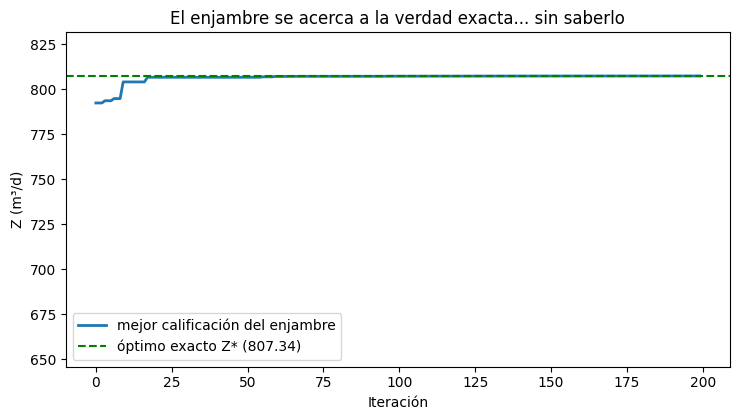

In [29]:
hidra.convergencia(historial_fritz, referencia=Z_exacto, etiqueta='mejor calificación del enjambre', etiqueta_ref='óptimo exacto Z*',   # la curva del enjambre contra la línea de linprog
                   ylabel='Z (m³/d)', titulo='El enjambre se acerca a la verdad exacta... sin saberlo', ylim_rel=(0.8, 1.03))

**Lectura.** El enjambre llega casi a la misma respuesta que `linprog`. Pero `linprog` **demuestra** que no hay nada mejor (el certificado del vértice);
el enjambre solo puede decir «es lo mejor que vi». Hoy sabemos que acertó porque tenemos la verdad exacta. En la sección 3 no la tendremos.

### 2.4 Las restricciones y la escala del castigo

El castigo del original (cambiar el signo) es **discontinuo**: una decisión que rompe la regla por un milímetro vale lo mismo que una que la rompe por un
metro. La alternativa es un castigo **graduado**, proporcional al exceso:

$$
\text{calificación}(\mathbf{p}) = \sum_i p_i - M \left[\, \sum_j \max(0,\ s_j - 3) + \max(0,\ s_h - 1.25) \,\right]
$$

**donde** $M$ es el castigo en m³/d por cada metro de exceso. Si $M$ es pequeño, a la partícula le **conviene** romper la regla: el agua extra vale más que la multa.

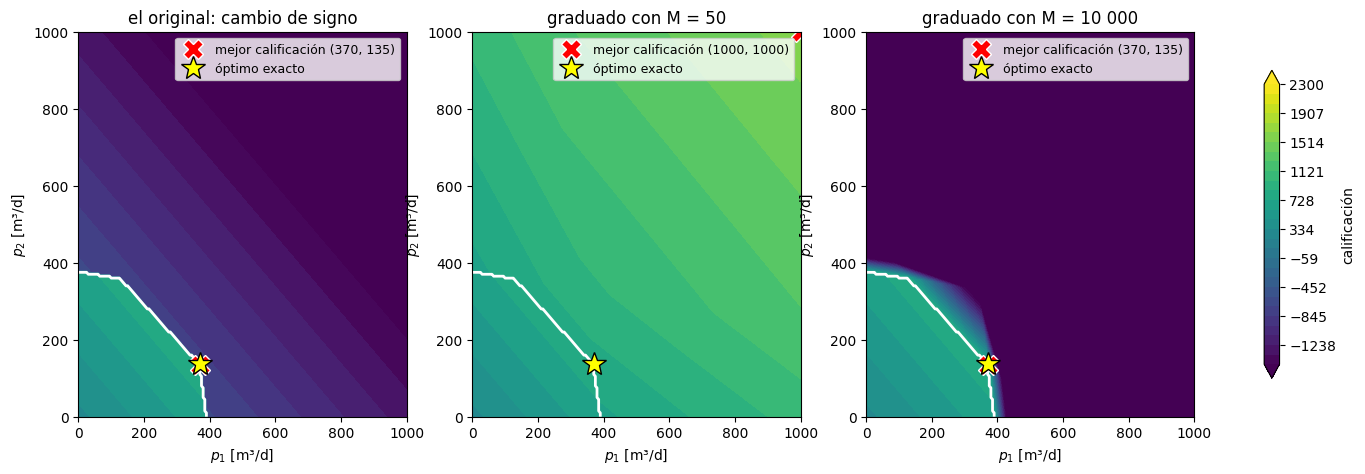

M =     50: p = [1000. 1000.  300.], abatimientos [8.17 8.44 4.3 ] m, humedal 3.90 m
M =  10000: p = [370.  137.3 300. ], abatimientos [2.99 1.68 2.66] m, humedal 1.25 m


In [30]:
def Pumping_graduado(x, M):                                 # la multa graduada: M por cada metro de exceso
    exceso = np.sum(np.maximum(alpha @ x - S_MAX, 0)) + max(alpha_h @ x - S_HUM, 0)   # metros que los pozos y el humedal se pasan de su límite
    return np.sum(x) - M * exceso                           # bombeo total menos la multa

hidra.paisajes_castigo(alpha, alpha_h, P3, S_MAX, S_HUM, exacto.x, Ms=(50, 10_000))   # el paisaje con el signo, con M = 50 y con M = 10 000

for M in (50, 10_000):                                      # una multa barata y una cara
    np.random.seed(0)                                       # fija el azar: así todos vemos el mismo resultado
    g, _ = pso.PSO(dict(problem, CostFunction=lambda x, M=M: Pumping_graduado(x, M)), MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)   # el enjambre con esa multa
    print(f"M = {M:6d}: p = {np.round(g['position'], 1)}, abatimientos {np.round(alpha @ g['position'], 2)} m, humedal {alpha_h @ g['position']:.2f} m")   # dónde terminó y si rompe las reglas

Con $M = 50$ la cima del paisaje está **fuera** de la región factible (la línea blanca) y el enjambre la encuentra: rompe las reglas. Con el cambio de signo
o con $M$ grande, la cima coincide con el vértice exacto. **El castigo debe estar en la escala de lo que se gana rompiendo la regla.**

<div style="border-left: 6px solid #C08A0B; background: #FBF1D6; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✔ Punto de control 2 · ⏸ Ejecuta hasta aquí</b> <span style="color:#54696F; font-size:0.8em;">· minuto 36 del cuaderno</span></p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Debes ver</b> · Debes ver: el enjambre en <b>807.34 m³/d</b> con p = (370.87, 136.47, 300), error 0.000 % contra linprog; con M = 50 el enjambre rompe las reglas (p₁ = p₂ = 1000) y con M = 10 000 vuelve al vértice.</p>
<p style="margin: 0; color:#54696F;">Si tu resultado no coincide, avisa en el chat antes de seguir; si coincide, espera: seguimos juntos.</p>
</div>

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 3 · LA AMPLIACIÓN NO LINEAL · PROGRAMA 2.4</p>

## 3 · El mismo problema, no lineal: el beneficio neto (15 min)

En la sección 2 el enjambre resolvió lo que `linprog` ya resolvía. Ahora el problema que justifica al enjambre: Fritz ya no quiere **el máximo de agua**,
quiere el **máximo beneficio**. Vende el agua, pero bombearla le cuesta, y el costo crece con el abatimiento.

### 3.1 Definición de la función objetivo

$$
\max\; B(\mathbf{p}) \;=\; P \sum_{i=1}^{3} p_i \;-\; \sum_{i=1}^{3} c_i\,p_i\,\big(\text{H}_i - h_i^0 + s_i(\mathbf{p})\big)
$$

**donde**:

- $P = 0.11$ \$ por m³ es el **precio** al que Fritz vende el agua.
- El segundo término es el **costo del bombeo**, la función objetivo 2 del cuaderno original de la sesión 3: $c_i$ es el coeficiente de costo
  ($0.01,\ 0.015,\ 0.02$), $\text{H}_i$ la cota del terreno (40 m), $h_i^0$ el nivel estático ($34,\ 34,\ 15$ m) y $s_i$ el abatimiento. La **altura de
  bombeo** $\text{H}_i - h_i^0 + s_i$ crece con el bombeo, así que el costo tiene un término **lineal** y uno **cuadrático** en el bombeo (el desarrollo, abajo).
- Ahora los **tres pozos** se deciden (de 0 a 500 m³/d): el contrato del pozo 3 se renegoció.

**Restricciones:** las mismas, $s_j \le 3$ m en los pozos y $s_h \le 1.25$ m en el humedal.

Como $s_i$ depende de los bombeos, $B$ es **no lineal**: ya no hay vértice que buscar, y `linprog` no puede resolverlo.

**La función objetivo, desarrollada.** El abatimiento sale de la matriz de respuesta, que es lineal en los bombeos: $s_i = \alpha_{i1}\,p_1 + \alpha_{i2}\,p_2 + \alpha_{i3}\,p_3$.
Una vez sustituido y desarrollada la función objetivo, se observa un **término cuadrático**:

$$
B(\mathbf{p}) \;=\; \underbrace{\sum_{i=1}^{3} \big[P - c_i\,(\text{H}_i - h_i^0)\big]\,p_i}_{\text{término lineal}} \;-\; \underbrace{\sum_{i=1}^{3}\sum_{j=1}^{3} c_i\,\alpha_{ij}\,p_i\,p_j}_{\text{término cuadrático}}
$$

El término cuadrático lleva los $p_i^2$ de cada pozo y los productos $p_i\,p_j$ entre pozos (lo que cada uno abate a los demás): es el que hace a $B$ no lineal.

**Con números**, el pozo 1 solo ($c_1 = 0.01$, $\text{H} - h^0 = 6$ m, $\alpha_{11} = 0.00678$ m por m³/d):

| bombeo $p_1$ [m³/d] | parte lineal $0.06\,p_1$ | parte cuadrática $0.0000678\,p_1^2$ | costo [\$/d] | ingreso $0.11\,p_1$ [\$/d] |
|:---:|:---:|:---:|:---:|:---:|
| 200 | 12.0 | 2.7 | 14.7 | 22 |
| 400 | 24.0 | 10.8 | 34.8 | 44 |

Al doblar el bombeo, la parte lineal se duplica y la cuadrática se **cuadruplica**: el costo crece 2.4 veces y el ingreso solo 2.

El primer corchete, $P - c_i\,(\text{H}_i - h_i^0)$, es lo que deja el **primer m³** de cada pozo: pozo 1, $0.11 - 0.06 = +0.05$; pozo 2, $0.11 - 0.09 = +0.02$;
pozo 3, $0.11 - 0.50 = -0.39$ \$/m³. El pozo 3 pierde dinero desde el primero. Los pozos 1 y 2 ganan al principio, y el término cuadrático los frena
antes de llegar a las reglas: por eso el óptimo queda adentro de la región.

👀 **¿Qué es la altura de bombeo?** La bomba sube el agua desde el nivel bombeado hasta el terreno, y esa altura es la que se paga. Tiene dos partes. $\text{H} - h^0$ es fija: qué tan hondo está el agua antes de bombear (6 m en los pozos 1 y 2, 25 m en el 3). $s$ es el abatimiento y **crece con el bombeo**: mientras más se bombea, más abajo queda el agua y más alto hay que subirla. Por eso el costo crece más rápido que el ingreso, y el pozo 3, con el agua a 25 m, no paga ni su primer m³.

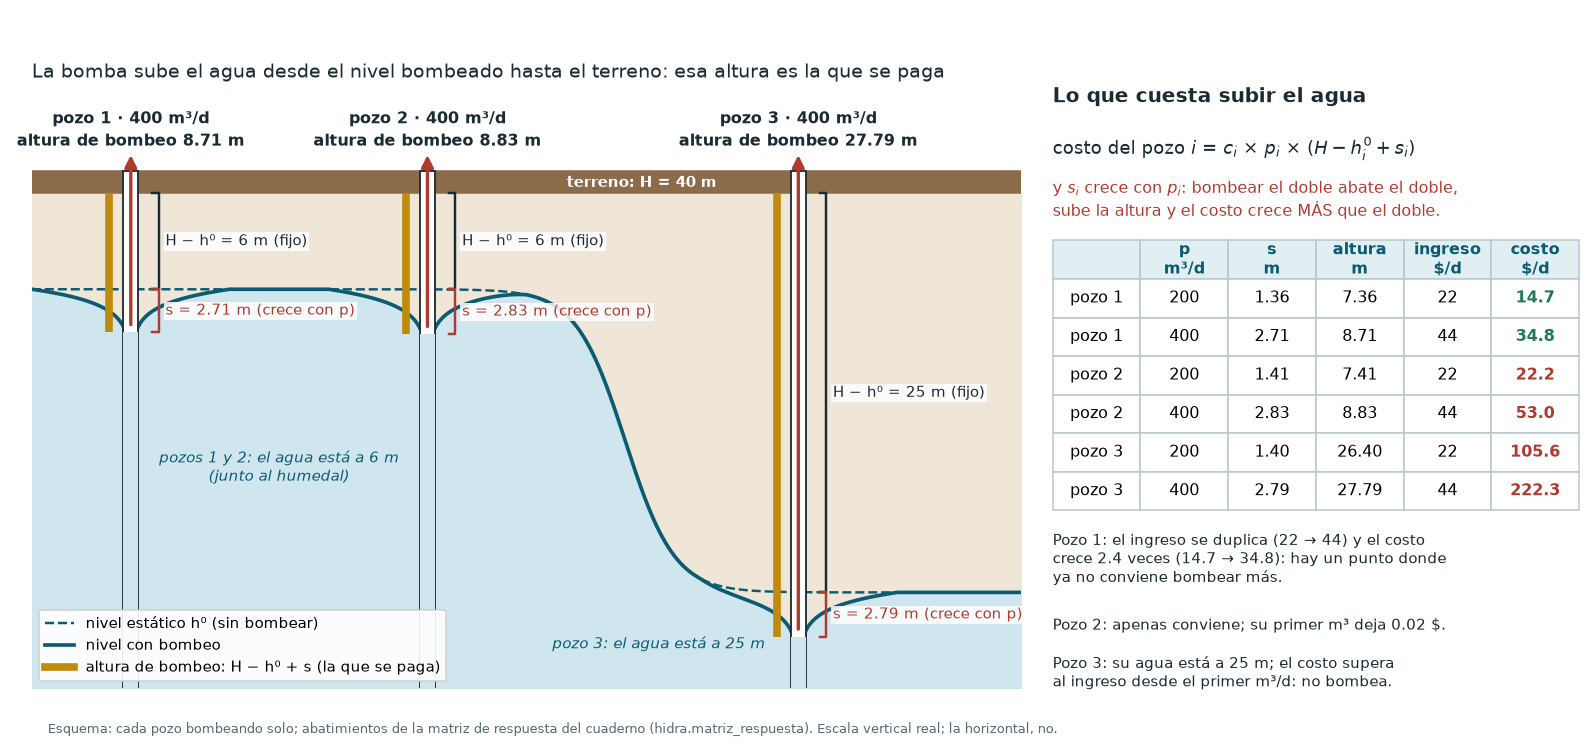

In [31]:
PRECIO = 0.11                                   # $ por m³
C_QP = np.array([0.01, 0.015, 0.02])            # coeficiente de costo de cada pozo
GSLEV = np.array([40.0, 40.0, 40.0])            # cota del terreno [m]
H0 = np.array([34.0, 34.0, 15.0])               # nivel estático [m]: los pozos 1 y 2 junto al humedal, someros; el 3, hondo

def beneficio(x, precio=PRECIO):                            # ingreso por el agua menos costo de bombearla [$/d]
    s = alpha @ x                                           # abatimiento en los tres pozos: s = α·p
    lineal = np.sum((precio - C_QP * (GSLEV - H0)) * x)     # término lineal: Σ [P − c_i (H_i − h⁰_i)] p_i
    cuadratico = np.sum(C_QP * x * s)                       # término cuadrático: Σ c_i p_i s_i (p por α·p)
    return lineal - cuadratico                              # beneficio = término lineal − término cuadrático

for p in [(200, 100, 0), (400, 100, 0), (300, 300, 100)]:   # tres decisiones de prueba
    x = np.array(p, float)                                  # la decisión como arreglo
    print(f"bombeos {p}: beneficio {beneficio(x):6.2f} $/d | pozos {np.round(alpha @ x, 2)} m | humedal {alpha_h @ x:.2f} m")   # su beneficio y sus abatimientos

bombeos (200, 100, 0): beneficio   7.71 $/d | pozos [1.46 0.92 0.34] m | humedal 0.52 m
bombeos (400, 100, 0): beneficio   9.05 $/d | pozos [2.81 1.13 0.56] m | humedal 0.86 m
bombeos (300, 300, 100): beneficio -39.54 $/d | pozos [2.46 2.54 1.36] m | humedal 1.18 m


👀 **El beneficio, en un dibujo.** Solo el pozo 1 bombeando, de 0 a 500 m³/d: el ingreso crece en línea recta con el bombeo, pero el costo crece cada vez más rápido porque el abatimiento sube la altura de bombeo. La diferencia, el beneficio, tiene un máximo en el interior: ahí ya no frena una regla, frena la economía.

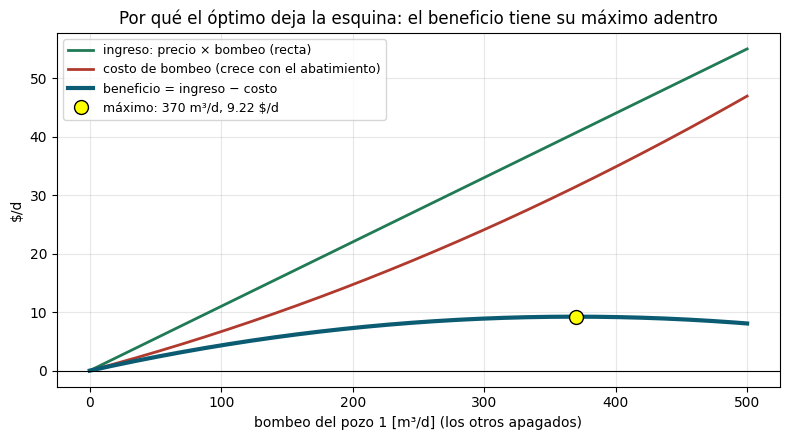

In [32]:
hidra.curva_beneficio(PRECIO, alpha, C_QP, GSLEV, H0, pozo=0)   # ingreso, costo y beneficio del pozo 1 solo

### 3.2 PSO contra la referencia

Sin `linprog`, ¿contra qué medimos al enjambre? Contra una **referencia** calculada aparte, probando todas las decisiones de 5 en 5 m³/d (más de un
millón; se puede hacer porque solo hay tres pozos y la matriz hace barata cada evaluación): la mejor es $\mathbf{p} = (360,\ 50,\ 0)$ m³/d, con
**9.48 \$/d**.

Elapsed time: 0.13 s
PSO:   p = [359.3  49.9   0. ] m³/d, beneficio 9.483 $/d
referencia: p = [360.  50.   0.] m³/d, beneficio 9.483 $/d
el enjambre queda arriba de la referencia por 0.000 $/d (la referencia va de 5 en 5 m³/d)


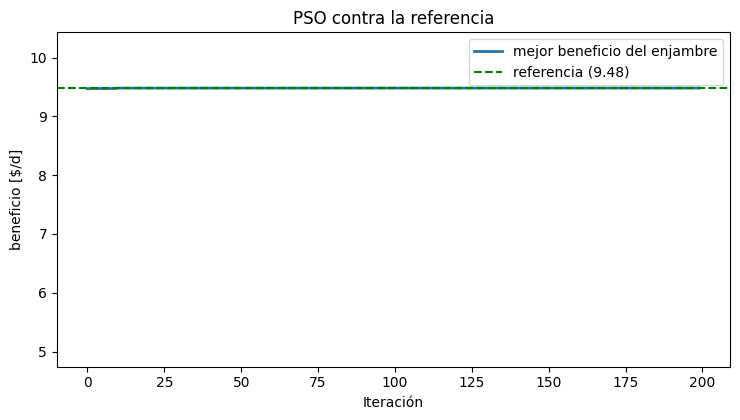

In [33]:
x_ref = np.array([360.0, 50.0, 0.0])                        # la referencia: la mejor decisión, calculada aparte de 5 en 5 m³/d
B_ref = beneficio(x_ref)                                    # su beneficio: 9.48 $/d

def Beneficio(x, M=10.0):                                   # la función que califica: beneficio menos la multa
    s = alpha @ x                                           # abatimiento de cada pozo: s = α·p
    lineal = np.sum((PRECIO - C_QP * (GSLEV - H0)) * x)     # término lineal: ingreso menos subir el agua desde el nivel estático
    cuadratico = np.sum(C_QP * x * s)                       # término cuadrático: subirla además los s metros que abate el bombeo
    exceso = np.sum(np.maximum(s - S_MAX, 0)) + max(alpha_h @ x - S_HUM, 0)   # metros que los pozos y el humedal se pasan de su límite
    return lineal - cuadratico - M * exceso                 # beneficio (lineal − cuadrático) menos la multa graduada

problema_B = {'CostFunction': Beneficio, 'nVar': 3, 'VarMin': 0, 'VarMax': 500, 'MinProblem': 0}   # el mismo diccionario; solo cambió la función (y se maximiza)
np.random.seed(0)                                           # fija el azar: así todos vemos el mismo resultado
pso.tic()                                                   # arranca el cronómetro
gbest_B, _ = pso.PSO(problema_B, MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)   # el enjambre sobre el beneficio
pso.toc()                                                   # imprime cuánto tardó
historial_B = list(pso.historial)                           # guarda la curva
print(f"PSO:   p = {np.round(gbest_B['position'], 1)} m³/d, beneficio {gbest_B['cost']:.3f} $/d")   # lo que encontró el enjambre
print(f"referencia: p = {x_ref} m³/d, beneficio {B_ref:.3f} $/d")
print(f"el enjambre queda {'arriba' if gbest_B['cost'] >= B_ref else 'abajo'} de la referencia por {abs(gbest_B['cost'] - B_ref):.3f} $/d (la referencia va de 5 en 5 m³/d)")

hidra.convergencia(historial_B, referencia=B_ref, etiqueta='mejor beneficio del enjambre', etiqueta_ref='referencia',
                   ylabel='beneficio [$/d]', titulo='PSO contra la referencia', ylim_rel=(0.5, 1.1))

El enjambre llega a la cima, e incluso puede quedar un poco **arriba** de la referencia: la referencia solo prueba múltiplos de 5 m³/d y el enjambre se mueve en continuo.

**La diferencia esencial con la sección 2:** el óptimo ya no está en una esquina. En la mejor decisión ninguna regla está en su límite (pozos 2.49, 0.73 y 0.47 m; humedal 0.70 m): lo que frena a Fritz no es la física,
es la **economía**. Bombear un m³/d más cuesta más de lo que vale, porque cada m³ adicional abate más y sube la altura de bombeo de todos. Y el pozo 3
no bombea: está hondo y su agua no paga su costo.

### 3.3 El enjambre llama directamente al simulador

Hasta aquí usamos la matriz porque el acuífero es lineal en las cargas. Pero el enjambre **no la necesita**: basta con que la calificación llame a
`hidra.simular`. Cada evaluación es ahora una solución completa de elementos finitos, así que usamos un presupuesto chico: 15 partículas × 30 iteraciones
= 450 corridas del simulador.

Elapsed time: 2.25 s
enjambre con el simulador: p = [359.3  49.9   0. ], beneficio 9.483 $/d (referencia 9.483), con solo 450 corridas


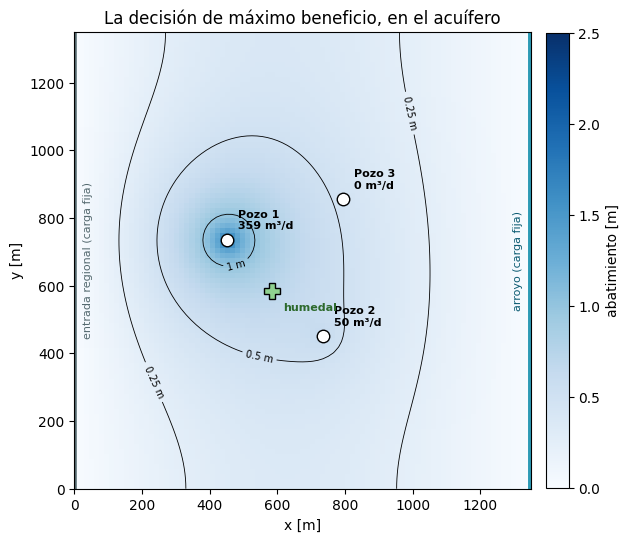

In [34]:
# Esta celda tarda unos segundos
def Beneficio_simulador(x, M=10.0):                         # la misma calificación, pero llamando al simulador
    r = hidra.simular(x)                                                          # 1 · una corrida completa del simulador
    costo = np.sum(C_QP * x * (GSLEV - H0 + r.abatimiento_pozos))                 # 2 · el costo con los abatimientos simulados
    exceso = np.sum(np.maximum(r.abatimiento_pozos - S_MAX, 0)) + max(r.abatimiento_humedal - S_HUM, 0)   # metros de exceso, con los abatimientos simulados
    return PRECIO * np.sum(x) - costo - M * exceso                                # 3 · igual que antes

np.random.seed(0)                                           # fija el azar: así todos vemos el mismo resultado
pso.tic()                                                   # arranca el cronómetro
gbest_s, _ = pso.PSO(dict(problema_B, CostFunction=Beneficio_simulador), MaxIter=30, PopSize=15, c1=1.5, c2=2, w=1, wdamp=0.95, verbose=False)   # 15 × 30 = 450 corridas del simulador
pso.toc()                                                   # imprime cuánto tardó
print(f"enjambre con el simulador: p = {np.round(gbest_s['position'], 1)}, beneficio {gbest_s['cost']:.3f} $/d (referencia {B_ref:.3f}), con solo 450 corridas")   # el resultado con el simulador en el lazo
hidra.mapa(hidra.simular(gbest_s['position']), titulo='La decisión de máximo beneficio, en el acuífero'); plt.show()   # el acuífero con esa decisión

Esta es la idea central de la simulación-optimización: **el optimizador propone, el simulador califica**. El precio es el número de corridas. Si mañana
el acuífero fuera libre o transitorio, este código seguiría funcionando; el de `linprog`, no.

<div style="border-left: 6px solid #2E9BB5; background: #E2EFF2; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✏️ Tu turno 3 · ¿Y si el agua vale más?</b> <span style="color:#54696F; font-size:0.8em;">· 2 min · la celda de abajo es tuya</span></p>
<p style="margin: 0;"><b style="color:#0B5B72;">Qué hacer</b></p>
<ol style="margin: 2px 0 8px 0; padding-left: 1.4em;"><li>Ejecuta la celda tal como está: el agua pasa de 0.11 a <b>0.16 $/m³</b> (<code>PRECIO_TT</code>).</li><li>Cambia <code>PRECIO_TT</code> a <b>0.08</b> y vuelve a ejecutar.</li></ol>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Qué observar</b> · el bombeo total y cuánto bombea cada pozo, frente a los 409 m³/d que daba el precio de 0.11.</p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Pregunta</b> · si el agua vale más, ¿Fritz bombea más o menos? ¿Por qué el pozo 3 sigue en cero?</p>
<details style="margin-top: 4px;"><summary style="cursor: pointer; color:#C08A0B;"><b>Cuando termines: lo que debías ver</b></summary>
<p style="margin: 4px 0 0 0;">Con 0.16 bombea 656 m³/d, (404, 252, 0); con 0.08 solo 148, (148, 0, 0). Mientras más vale el agua, más conviene bombear: cada m³ paga más de lo que cuesta subirlo. El pozo 3 sigue en cero porque su agua está a 25 m de profundidad: subirla cuesta más de lo que vale, incluso a 0.16.</p></details>
</div>

In [35]:
PRECIO_TT = 0.16                                            # ← cambia el precio del agua ($ por m³)

def Beneficio_tt(x, M=10.0):                                # la misma función que califica de 3.2; solo cambia el precio
    s = alpha @ x                                           # abatimiento de cada pozo: s = α·p
    lineal = np.sum((PRECIO_TT - C_QP * (GSLEV - H0)) * x)  # término lineal, ahora con PRECIO_TT
    cuadratico = np.sum(C_QP * x * s)                       # término cuadrático: no depende del precio
    exceso = np.sum(np.maximum(s - S_MAX, 0)) + max(alpha_h @ x - S_HUM, 0)   # metros que los pozos y el humedal se pasan de su límite
    return lineal - cuadratico - M * exceso                 # beneficio con PRECIO_TT menos la multa

np.random.seed(0)                                           # fija el azar: así todos vemos el mismo resultado
g_tt, _ = pso.PSO(dict(problema_B, CostFunction=Beneficio_tt), MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)   # el mismo enjambre de 3.2, con el precio nuevo
print(f"con {PRECIO_TT:.2f} $/m³: p = {np.round(g_tt['position'])} m³/d, total {g_tt['position'].sum():.0f} m³/d")      # lo que bombea con el precio nuevo
print(f"con 0.11 $/m³: p = {np.round(gbest_B['position'])} m³/d, total {gbest_B['position'].sum():.0f} m³/d   (sección 3.2)")   # lo que bombeaba antes


con 0.16 $/m³: p = [404. 252.   0.] m³/d, total 656 m³/d
con 0.11 $/m³: p = [359.  50.   0.] m³/d, total 409 m³/d   (sección 3.2)


<div style="border-left: 6px solid #C08A0B; background: #FBF1D6; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✔ Punto de control 3 · ⏸ Ejecuta hasta aquí</b> <span style="color:#54696F; font-size:0.8em;">· minuto 51 del cuaderno</span></p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Debes ver</b> · Debes ver: el beneficio máximo <b>9.483 $/d</b> con p ≈ (359, 50, 0), igual que la referencia; ninguna regla activa; y el enjambre con <code>hidra.simular</code> llega al mismo punto con 450 corridas.</p>
<p style="margin: 0; color:#54696F;">Si tu resultado no coincide, avisa en el chat antes de seguir; si coincide, espera: seguimos juntos.</p>
</div>

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 4 · OTRA GEOLOGÍA, OTRO ÓPTIMO · EL PUENTE A LA SESIÓN 4</p>

## 4 · Otra geología, otro óptimo (7 min)

Todo lo anterior supone el acuífero **homogéneo**. `hidra` trae diez geologías heterogéneas posibles, todas compatibles con lo que sabemos del acuífero.
Con cada una, cada pozo abate distinto. ¿Sigue sirviendo la respuesta que le dimos a Fritz?

**El experimento:** tomamos la decisión óptima de la sección 2 (807.3 m³/d, calculada con el acuífero homogéneo), la simulamos **tal cual** en otra
geología y vemos si sigue cumpliendo las reglas. Luego calculamos el óptimo de esa geología. Cambia solo el número de `GEOLOGIA` (de 0 a 9).

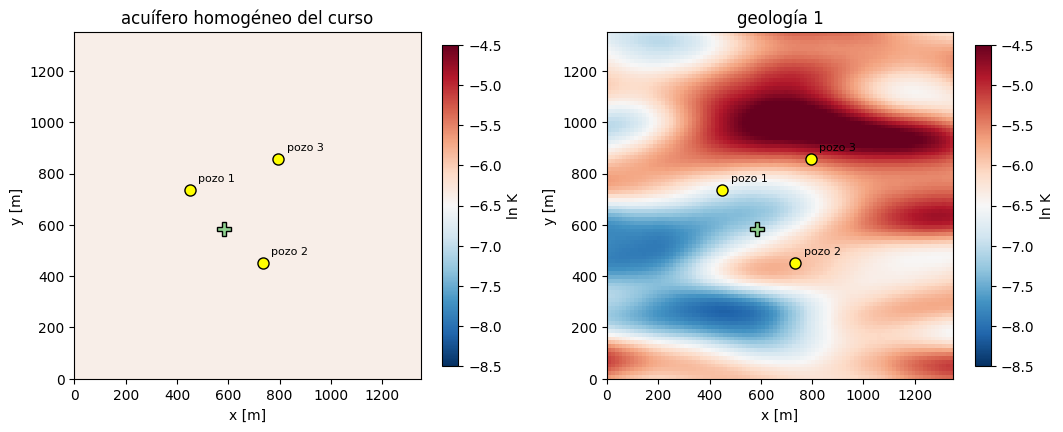

La decisión del homogéneo [371. 136. 300.] en la geología 1: pozos [3.21 1.08 1.11] m, humedal 0.85 m  ->  ROMPE LAS REGLAS


El óptimo de la geología 1: p = [324. 381.], total 1005.2 m³/d (el homogéneo daba 807.3)


In [36]:
GEOLOGIA = 1                                                # ← cambia el número de la geología: de 0 a 9
hidra.mapas_geologias((None, GEOLOGIA))                     # el acuífero que supusimos y el que podría ser

x_hom = np.array([exacto.x[0], exacto.x[1], P3])            # la decisión óptima del homogéneo (sección 2)
r = hidra.simular(x_hom, geologia=GEOLOGIA)                 # esa misma decisión, en la otra geología
cumple = (r.abatimiento_pozos <= S_MAX).all() and r.abatimiento_humedal <= S_HUM   # ¿cumple todas las reglas?
print(f"La decisión del homogéneo {np.round(x_hom)} en la geología {GEOLOGIA}: pozos {np.round(r.abatimiento_pozos, 2)} m, "
      f"humedal {r.abatimiento_humedal:.2f} m  ->  {'cumple' if cumple else 'ROMPE LAS REGLAS'}")

a_g, ah_g = hidra.matriz_respuesta(GEOLOGIA), hidra.coeficientes_humedal(GEOLOGIA)   # el óptimo de esa geología: la programación lineal de 2.2
nuevo = linprog(c=[-1, -1], A_ub=np.vstack([a_g[:, :2], ah_g[:2]]), b_ub=np.append(S_MAX - a_g[:, 2] * P3, S_HUM - ah_g[2] * P3),
                bounds=[(0, 1000)] * 2, method='highs')     # bombas de 0 a 1 000
print(f"El óptimo de la geología {GEOLOGIA}: " + (f"p = {np.round(nuevo.x)}, total {nuevo.x.sum() + P3:.1f} m³/d (el homogéneo daba {Z_exacto:.1f})"
      if nuevo.status == 0 else "no hay decisión legal: el pozo 3, con su contrato de 300 m³/d, ya rompe una regla"))

<details><summary><b>Lo que debías ver, geología por geología</b></summary>

| geología | la decisión del homogéneo (371, 136, 300) | el óptimo de esa geología [m³/d] |
|:---:|:---:|:---:|
| 0 | **rompe** (pozo 1 a 8.37 m) | 330.5 |
| 1 | **rompe** (pozo 1 a 3.21 m) | 1 005.2 |
| 2 | **rompe** (pozo 3 a 4.84 m) | sin decisión legal |
| 3 | **rompe** (pozo 1 a 3.64 m) | 738.7 |
| 4 | cumple, pero desperdicia agua | 1 119.8 |
| 5 | **rompe** (pozo 3 a 4.56 m) | sin decisión legal |
| 6 | **rompe** (pozo 3 a 4.62 m) | sin decisión legal |
| 7 | **rompe** (pozo 1 a 3.92 m, humedal 1.38 m) | 736.2 |
| 8 | cumple, pero desperdicia agua | 1 513.6 |
| 9 | **rompe** (pozo 3 a 3.01 m) | 816.0 |

En 8 de las 10 geologías la respuesta que le daríamos a Fritz rompe una regla; en las otras 2 deja agua sin bombear.
</details>

La respuesta que le damos a Fritz depende de una geología que **no conocemos**: el óptimo de un acuífero supuesto no es el óptimo del acuífero real,
y puede ni siquiera ser legal. La sesión 4 toma muchas geologías a la vez: ¿qué decisión resiste a todas?

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 5 · CIERRE Y TAREA</p>

## 5 · Cierre: lo que el enjambre sí y no hace (5 min)

| | Programación lineal (sesión 1) | Enjambre de partículas (hoy) |
|---|---|---|
| Qué necesita | la matriz y todo lineal | solo poder calificar una decisión |
| Problema lineal (sección 2) | exacto, con certificado | casi igual, sin certificado |
| Problema no lineal (sección 3) | no aplica | lo resuelve; se valida contra una referencia |
| Restricciones | aparte, exactas | dentro de la calificación: el castigo debe estar en la escala correcta |
| Lo que hay que reportar | el óptimo | el óptimo de varias corridas, con su estadística |

**El martes que viene:** Fritz ya no quiere solo un número. El costo de hoy, el agua y la necesidad de cubrirla **se pelean entre sí**: varios objetivos a la
vez, con OMOPSO y el frente de Pareto.

### Tarea 2 (asíncrono, unas 2 horas)

`Tarea_2_estudiante.ipynb`, la misma para todos y con los datos de hoy: dos etapas sobre el algoritmo (un paso de la partícula a mano; apagar un término y cuándo parar) y luego la ruta de este cuaderno, desde tu propia función con PSO hasta las restricciones y su
castigo, el enjambre contra la verdad exacta, las semillas, el beneficio neto contra la referencia, el precio que mueve al óptimo y otra geología. Es el trabajo
asíncrono de la sesión y se califica: ofrece 12 puntos y la calificación se cierra en 10, tú eliges qué contestar; se aprueba con 6 de 10; con 2 de los 4 cuadernos de tarea aprobados, el examen del curso está aprobado. Entrega antes del 17 de noviembre.

### Referencias

- Kennedy, J. y Eberhart, R. (1995). Particle swarm optimization. *Proceedings of ICNN'95*, 4, 1942–1948.
- Clerc, M. y Kennedy, J. (2002). The particle swarm: explosion, stability, and convergence in a multidimensional complex space. *IEEE Transactions on Evolutionary Computation*, 6(1), 58–73.
- Clerc, M. (2010). *Particle Swarm Optimization*. John Wiley & Sons.
- Peralta, R. C. (2012). *Groundwater Optimization Handbook*. CRC Press. (El problema de los tres pozos.)
- Surjanovic, S. y Bingham, D. *Virtual Library of Simulation Experiments: Test Functions*. https://www.sfu.ca/~ssurjano/ (Sphere y Ackley.)

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">APÉNDICE · EN CASA · LO QUE NO CABE EN LA SESIÓN</p>

## Apéndice · En casa

Estas celdas salieron de la sesión para que el cuaderno quepa en el tiempo. Usan variables de las secciones de arriba (`Ackley`, `problem`, `alpha`,
`exacto`, `beneficio`…), así que **ejecuta el cuaderno completo en orden** antes de correrlas. Son cinco bloques: tres ejemplos de uso de PSO, la animación
del enjambre de Fritz sobre la región factible y el barrido de precios. La Tarea 2 usa ideas de los cinco.

#### Ejemplo 4 · Convergencia: el impacto de los parámetros

El mismo enjambre sobre Ackley de 10 variables, con **tres ajustes de la inercia** y la misma semilla:

| Ajuste | `w` | `wdamp` | Qué esperamos (lámina *Convergencia: el impacto de los parámetros*) |
|---|---|---|---|
| A · el del curso | 1.0 | 0.995 | explora al principio y explota al final |
| B · inercia baja fija | 0.4 | 1.0 | explota desde el inicio: rápido, pero puede atorarse |
| C · inercia alta sin amortiguar | 1.1 | 1.0 | fuera del rango estable: el enjambre no se calma |

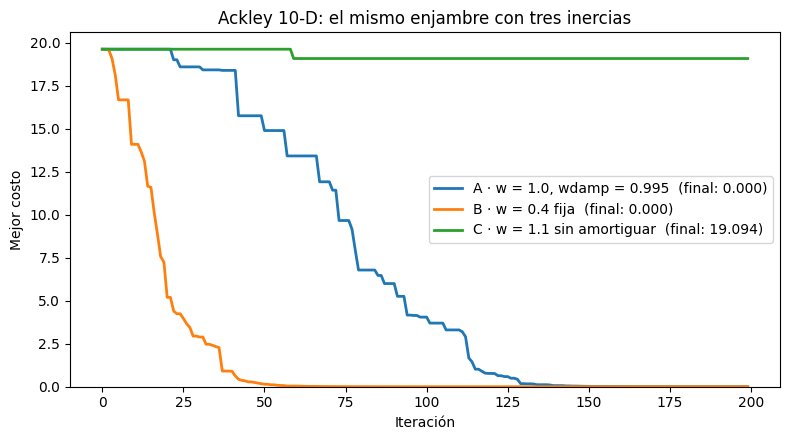

In [37]:
problema_ackley10 = {'CostFunction': Ackley, 'nVar': 10, 'VarMin': -32.768, 'VarMax': 32.768}   # Ackley en 10 variables, en su dominio estándar
ajustes = {'A · w = 1.0, wdamp = 0.995': (1.0, 0.995), 'B · w = 0.4 fija': (0.4, 1.0), 'C · w = 1.1 sin amortiguar': (1.1, 1.0)}   # tres inercias para comparar

historiales = {}                                            # aquí se guarda la curva de cada una
for nombre, (w_, wdamp_) in ajustes.items():                # una corrida por inercia
    np.random.seed(2)                                       # la misma semilla para las tres
    g, _ = pso.PSO(problema_ackley10, MaxIter=200, PopSize=30, c1=1.5, c2=2, w=w_, wdamp=wdamp_, verbose=False)   # el enjambre con esa inercia
    historiales[f'{nombre}  (final: {g["cost"]:.3f})'] = list(pso.historial)   # guarda su curva
hidra.convergencias(historiales, titulo='Ackley 10-D: el mismo enjambre con tres inercias')   # las tres curvas juntas

Una curva que baja rápido y se queda plana lejos de cero **convergió prematuramente**; una curva plana desde el principio **no converge**. Con esta semilla
la inercia baja (B) gana en rapidez; con las semillas 0 a 9, A queda atrapada 1 vez de 10, B 2 veces y C las 10. Rápido no es lo mismo que confiable.

✏️ **Inténtalo:** agrega un ajuste D con `c1 = c2 = 1.49445` y `w = 0.729` fija: los valores de constricción de Clerc y Kennedy (2002).

#### Ejemplo 6 · Tu propia función: maximizar y reparar

Para resolver **tu** problema basta escribir una función que reciba el vector de decisión y devuelva **un número**. Dos claves del diccionario cambian
el comportamiento: `'MinProblem': 0` para **maximizar**, y `'ResFunction'` para **reparar** cada posición después de moverla (por ejemplo, fijar una variable).

Ejemplo: maximizar $f(x_1, x_2) = 10 - (x_1 - 1)^2 - (x_2 + 2)^2$, cuyo máximo es 10 en $(1, -2)$, pero con $x_2$ fijo en 0 (entonces el máximo es 6, en $(1, 0)$).

In [38]:
def colina(x):                                              # una colina con máximo 10 en (1, −2)
    return 10 - (x[0] - 1)**2 - (x[1] + 2)**2

def fija_x2(x):                                             # una reparación de ejemplo
    x[1] = 0.0                # reparación: x2 siempre vale 0
    return x                                                # la decisión reparada

for nombre, prob in [('libre', {'CostFunction': colina, 'nVar': 2, 'VarMin': -5, 'VarMax': 5, 'MinProblem': 0}),   # dos problemas: libre y con x2 reparado
                     ('con x2 = 0', {'CostFunction': colina, 'nVar': 2, 'VarMin': -5, 'VarMax': 5, 'MinProblem': 0, 'ResFunction': fija_x2})]:
    np.random.seed(0)                                       # fija el azar: así todos vemos el mismo resultado
    g, _ = pso.PSO(prob, MaxIter=100, PopSize=30, c1=1.5, c2=2, w=1, wdamp=0.99, verbose=False)   # el enjambre maximiza la colina
    print(f"{nombre:11s}: máximo {g['cost']:.4f} en {np.round(g['position'], 4)}")   # dónde quedó el máximo

libre      : máximo 10.0000 en [ 1. -2.]
con x2 = 0 : máximo 6.0000 en [1. 0.]


#### Ejemplo 7 · La animación: el enjambre en movimiento

El bloque 3 del paso a paso, guardando las posiciones de cada iteración sobre las curvas de nivel de Ackley. Se guarda en `Información/figuras/enjambre_ackley.gif`.

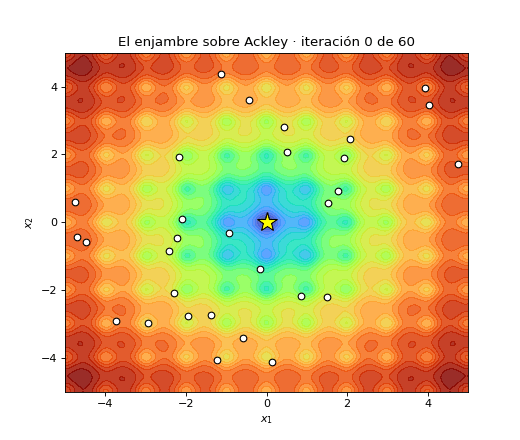

In [39]:
np.random.seed(3)                                           # fija el azar (semilla 3)
PopSize, MaxIter = 30, 60                                   # 30 partículas, 60 iteraciones
w, wdamp, c1, c2 = 1.0, 0.95, 1.5, 2.0                      # inercia, su amortiguación, peso de la memoria y peso del grupo
posicion = np.random.uniform(-5, 5, (PopSize, 2)); velocidad = np.zeros((PopSize, 2))   # posiciones al azar, velocidades cero
mejor_pos_propia = posicion.copy(); mejor_costo_propio = np.array([Ackley(x) for x in posicion])   # p = donde nacieron, y su costo
k = mejor_costo_propio.argmin(); g_pos, g_costo = mejor_pos_propia[k].copy(), mejor_costo_propio[k]   # g = la mejor (mínimo)
historia = [posicion.copy()]                                # guarda dónde está cada partícula, iteración por iteración
for it in range(MaxIter):                                   # una vuelta por iteración
    for i in range(PopSize):                                # una vuelta por partícula
        velocidad[i] = (w * velocidad[i] + c1 * np.random.rand(2) * (mejor_pos_propia[i] - posicion[i]) + c2 * np.random.rand(2) * (g_pos - posicion[i]))   # inercia + memoria + grupo
        posicion[i] = np.clip(posicion[i] + velocidad[i], -5, 5)   # se mueve y se acota
        c = Ackley(posicion[i])                             # se califica
        if c < mejor_costo_propio[i]:                       # ¿mejoró su récord?
            mejor_pos_propia[i], mejor_costo_propio[i] = posicion[i].copy(), c   # actualiza su mejor punto p
            if c < g_costo:                                 # ¿y el del grupo?
                g_pos, g_costo = posicion[i].copy(), c      # actualiza g
    w *= wdamp                                              # la inercia se amortigua
    historia.append(posicion.copy())                        # guarda la iteración

hidra.animar_enjambre(historia, 'Información/figuras/enjambre_ackley.gif', f=Ackley, lim=(-5, 5), titulo='El enjambre sobre Ackley')   # el GIF del enjambre

### 2.5 La animación sobre la región factible

El enjambre visto en el plano $(p_1, p_2)$: el polígono es la región factible con el humedal, la estrella el óptimo exacto. Se guarda en `Información/figuras/enjambre_fritz.gif`.

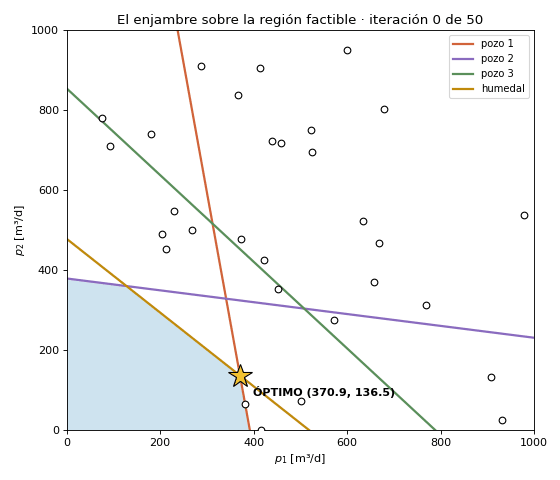

In [40]:
def calif_2d(q):                                            # la calificación de Fritz con solo p1 y p2 (p3 fijo)
    return Pumping_graduado(np.array([q[0], q[1], P3]), 10_000)   # multa graduada con M = 10 000

np.random.seed(7)                                           # fija el azar (semilla 7)
PopSize, MaxIter = 30, 50                                   # 30 partículas, 50 iteraciones
w, wdamp, c1, c2 = 1.0, 0.95, 1.5, 2.0                      # inercia, su amortiguación, peso de la memoria y peso del grupo
posicion = np.random.uniform(0, 1000, (PopSize, 2)); velocidad = np.zeros((PopSize, 2))   # bombeos al azar, velocidades cero
mejor_pos_propia = posicion.copy(); mejor_costo_propio = np.array([calif_2d(q) for q in posicion])   # p = donde nacieron, y su calificación
k = mejor_costo_propio.argmax(); g_pos, g_costo = mejor_pos_propia[k].copy(), mejor_costo_propio[k]   # g = la mejor (máximo)
historia = [posicion.copy()]                                # guarda dónde está cada partícula, iteración por iteración
for it in range(MaxIter):                                   # una vuelta por iteración
    for i in range(PopSize):                                # una vuelta por partícula
        velocidad[i] = (w * velocidad[i] + c1 * np.random.rand(2) * (mejor_pos_propia[i] - posicion[i]) + c2 * np.random.rand(2) * (g_pos - posicion[i]))   # inercia + memoria + grupo
        posicion[i] = np.clip(posicion[i] + velocidad[i], 0, 1000)   # se mueve y se acota a la bomba
        c = calif_2d(posicion[i])                           # se califica
        if c > mejor_costo_propio[i]:                 # maximizar: ahora «mejor» es «mayor»
            mejor_pos_propia[i], mejor_costo_propio[i] = posicion[i].copy(), c   # actualiza su mejor punto p
            if c > g_costo:                                 # ¿y el del grupo?
                g_pos, g_costo = posicion[i].copy(), c      # actualiza g
    w *= wdamp                                              # la inercia se amortigua
    historia.append(posicion.copy())                        # guarda la iteración

hidra.animar_enjambre(historia, 'Información/figuras/enjambre_fritz.gif', titulo='El enjambre sobre la región factible', fps=7,   # el GIF sobre la región factible
                      region=dict(A=A, b=b, nombres=['pozo 1', 'pozo 2', 'pozo 3', 'humedal'], p_optimo=exacto.x))

### 3.4 El óptimo se mueve con el precio

¿Qué pasa si cambia el precio del agua? Comparamos con la versión **lineal** del mismo problema: el costo sin el abatimiento ($c_i\,p_i\,(\text{H}_i - h_i^0)$),
que `linprog` sí resuelve.

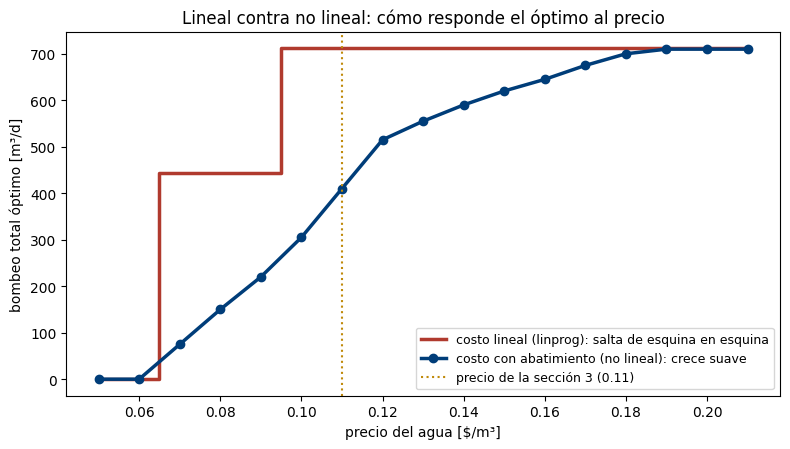

In [41]:
g = np.arange(0, 501, 5.0)                                  # la malla: cada pozo de 0 a 500 m³/d, de 5 en 5
X_malla = np.array(np.meshgrid(g, g, g, indexing='ij')).reshape(3, -1).T          # 1 030 301 decisiones
S_malla = X_malla @ alpha.T                                 # sus abatimientos, todos a la vez
legal = (S_malla <= S_MAX).all(axis=1) & (X_malla @ alpha_h <= S_HUM)   # cuáles cumplen todas las reglas
X_leg, S_leg = X_malla[legal], S_malla[legal]               # solo las legales

def beneficio_malla(precio):                                # el beneficio de todas las legales con un precio
    return precio * X_leg.sum(1) - (C_QP * X_leg * (GSLEV - H0 + S_leg)).sum(1)   # la fórmula de 3.1

precios = np.round(np.arange(0.05, 0.22, 0.01), 2)          # de 0.05 a 0.21 $/m³
total_no_lineal, total_lineal = [], []                      # el bombeo total óptimo con cada precio, en los dos modelos
for pr in precios:                                          # un precio por vuelta
    Bp = beneficio_malla(pr); total_no_lineal.append(X_leg[np.argmax(Bp)].sum())   # no lineal: la mejor de la malla
    r = linprog(-(pr - C_QP * (GSLEV - H0)), A_ub=np.vstack([alpha, alpha_h]), b_ub=[S_MAX] * 3 + [S_HUM], bounds=[(0, 500)] * 3, method='highs')   # lineal: costo sin el abatimiento, con linprog
    total_lineal.append(r.x.sum())                          # guarda el total

hidra.optimo_contra_precio(precios, total_lineal, total_no_lineal, PRECIO)   # cómo se mueve el óptimo con el precio

En el problema **lineal** el óptimo solo puede estar en una esquina: con el precio bajo no conviene bombear, y en cuanto conviene, se bombea **todo** lo que
las reglas permiten. En el **no lineal** el óptimo crece poco a poco con el precio, hasta que choca con las reglas y se vuelve igual al lineal. Esa zona
intermedia, donde la economía manda, ya no la resuelve `linprog`. Aquí la física es lineal y el beneficio es cuadrático, así que un optimizador clásico con
gradiente también la resolvería; el enjambre se gana su lugar cuando la calificación es una **corrida del simulador** sin fórmula a la vista (sección 3.3).